# Safe Gardens: Plant Leaf Disease Detection
**Automated detection and classification of plant leaf diseases using colour-space segmentation, texture feature analysis and deep learning**

ARTI 403 – Image Processing · Group 2 · Imam Abdulrahman Bin Faisal University

| No. | Student | ID | Role |
|---|---|---|---|
| 1 | Nawaf Rabee Shahbal (Leader) | 2240009025 | Project lead & pipeline architect |
| 2 | Abbas Abdulaziz Al Thunayan | 2240004112 | Pre-processing |
| 3 | Mohammed Nasser Al-Marhoon | 2240005893 | Colour segmentation |
| 4 | Faisal Abdullah Alshehri | 2240001737 | Morphology & feature analysis |
| 5 | Saad Abdulaziz Alshehri | 2240006495 | Machine learning & CNN |
| 6 | Mohammed Sameer Alajlan | 2240002025 | Evaluation & visualisation |

This notebook contains the **complete implementation**, in order:

0. Setup and configuration
1. Dataset download and stratified split
2. Pre-processing (Gaussian → bilateral → CLAHE on L\*)
3. Colour-space segmentation (HSV / CIELAB, Otsu, K-means) and morphology
4. Feature extraction (colour moments, GLCM, LBP, shape, HOG)
5. Classical classifiers (SVM, Random Forest): feature groups, ablation, robustness
6. MobileNetV2 transfer-learning benchmark
7. Results, evaluation and figures
8. Inference on a single leaf

The long-running steps (feature extraction for 11k images ≈ 25 min, classical experiments ≈ 20 min, CNN training ≈ 55 min on a 2-core CPU) save their results to `data/cache/`, `models/` and `results/`. When those files exist they are reused; set the flags in the setup cell to `True` to recompute everything from scratch.

## 0. Setup

In [1]:
import argparse, collections, glob, json, math, os, random, subprocess, sys, time, warnings
import urllib.parse, urllib.request
from concurrent.futures import ThreadPoolExecutor
from multiprocessing import Pool

import cv2
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from IPython.display import Image as ShowImage, display
from scipy import ndimage as ndi
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.transforms import v2

DOWNLOAD_DATA       = False   # download the PlantVillage subset (~1 min)
RECOMPUTE_FEATURES  = False   # ~25 min on 2 CPU cores
RECOMPUTE_SEG_EVAL  = False   # ~5 min
RETRAIN_CLASSICAL   = False   # ~20 min
RETRAIN_CNN         = False   # ~55 min on CPU (8 epochs), a few minutes on a GPU
plt.rcParams['figure.dpi'] = 110

### 0.1 Configuration

```text
Central configuration for the Safe Gardens pipeline.
```

In [2]:
ROOT = os.path.abspath("..")   # this notebook lives in notebooks/
DATA_DIR = os.environ.get("SAFE_GARDENS_DATA", os.path.join(ROOT, "data", "plantvillage"))
COLOR_DIR = os.path.join(DATA_DIR, "color")          # RGB leaf images, one folder per class
SEGMENTED_DIR = os.path.join(DATA_DIR, "segmented")  # PlantVillage background-removed references
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
TABLE_DIR = os.path.join(RESULTS_DIR, "tables")
MODEL_DIR = os.path.join(ROOT, "models")
CACHE_DIR = os.path.join(ROOT, "data", "cache")
PRETRAINED_MNV2 = os.environ.get(
    "MNV2_WEIGHTS", os.path.join(ROOT, "data", "weights", "mobilenetv2_1.0-0c6065bc.pth"))

SEED = 42
IMG_SIZE = 256          # all images are resized to 256 x 256 before processing
HOG_SIZE = 128          # HOG is computed on a 128 x 128 grey image
CNN_SIZE = 224          # MobileNetV2 input resolution
SPLIT = (0.70, 0.15, 0.15)  # stratified train / validation / test

# Preprocessing parameters
GAUSS_KSIZE, GAUSS_SIGMA = 5, 1.0
BILATERAL_D, BILATERAL_SIGMA_COLOR, BILATERAL_SIGMA_SPACE = 9, 50, 50
CLAHE_CLIP, CLAHE_TILE = 2.0, (8, 8)

# Segmentation parameters
KMEANS_K = 3
MORPH_KERNEL = 5

for d in (RESULTS_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)


def pretty(cls_name):
    """'Tomato___Early_blight' -> 'Tomato: Early blight'."""
    crop, _, disease = cls_name.partition("___")
    crop = crop.replace("_", " ").replace(",", "").replace("(including sour)", "").replace("(maize)", "").strip()
    return f"{crop}: {disease.replace('_', ' ').strip()}"

## 1. Dataset
PlantVillage (Hughes & Salathé, 2015): 38 classes, 14 crop species, 256×256 RGB. We use a seeded, class-balanced subset of up to 300 images per class (11,227 images), split 70/15/15 with stratification, plus 555 background-removed reference images used as ground-truth leaf masks.

### 1.1 Reproducible download

```text
Download a reproducible, class-balanced subset of the PlantVillage dataset.

The PlantVillage images (Hughes & Salathe, 2015) are mirrored in the public
GitHub repository spMohanty/PlantVillage-Dataset. This script:
  1. lists every image path in that repository (blob-less git clone, no images),
  2. draws a seeded random sample of N images per class (raw/color),
  3. also pulls the matching "segmented" (background-removed) version for a
     subset of the sampled images; these are used as reference leaf masks to
     score our segmentation,
  4. downloads the files in parallel from raw.githubusercontent.com.

Usage:
    python scripts/download_dataset.py --per-class 200 --seg-per-class 10
```

In [3]:
REPO = "https://github.com/spMohanty/PlantVillage-Dataset"
RAW = "https://raw.githubusercontent.com/spMohanty/PlantVillage-Dataset/master/"


def list_repo_files(workdir):
    """Clone the repository without file contents and list all image paths."""
    if not os.path.isdir(os.path.join(workdir, ".git")):
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--no-checkout", "-q", REPO, workdir], check=True)
    out = subprocess.run(["git", "-C", workdir, "ls-tree", "-r", "--name-only",
                          "HEAD", "raw/color", "raw/segmented"],
                         check=True, capture_output=True, text=True).stdout
    return out.splitlines()


def select(paths, per_class, seg_per_class, seed):
    """Seeded, class-balanced sample of colour images + matching masks."""
    rng = random.Random(seed)
    seg = {p for p in paths if p.startswith("raw/segmented/")}
    by_class = collections.defaultdict(list)
    for p in paths:
        if p.startswith("raw/color/"):
            by_class[p.split("/")[2]].append(p)
    colour, masks = [], []
    for cls in sorted(by_class):
        files = sorted(by_class[cls])
        rng.shuffle(files)
        pick = files[:per_class]
        colour += pick
        n = 0
        for p in pick:
            stem = os.path.splitext(os.path.basename(p))[0]
            s = f"raw/segmented/{cls}/{stem}_final_masked.jpg"
            if s in seg and n < seg_per_class:
                masks.append(s)
                n += 1
    return colour, masks


def fetch(rel, out_root):
    dst = os.path.join(out_root, rel.replace("raw/", "", 1))
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        return True
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    url = RAW + urllib.parse.quote(rel)
    for _ in range(3):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                data = r.read()
            with open(dst, "wb") as f:
                f.write(data)
            return True
        except Exception:
            continue
    return False


def download_dataset(per_class=300, seg_per_class=15, seed=SEED, out=DATA_DIR,
                     listing_dir="/tmp/PlantVillage-listing", workers=32):
    a = argparse.Namespace(per_class=per_class, seg_per_class=seg_per_class, seed=seed, out=out,
                           listing_dir=listing_dir, workers=workers)

    paths = list_repo_files(a.listing_dir)
    colour, masks = select(paths, a.per_class, a.seg_per_class, a.seed)
    todo = colour + masks
    print(f"{len(colour)} colour images, {len(masks)} reference masks")
    ok = 0
    with ThreadPoolExecutor(a.workers) as ex:
        for i, r in enumerate(ex.map(lambda p: fetch(p, a.out), todo), 1):
            ok += r
            if i % 500 == 0:
                print(f"  {i}/{len(todo)}", flush=True)
    print(f"downloaded {ok}/{len(todo)} files into {os.path.abspath(a.out)}")
    return ok == len(todo)

In [4]:
if DOWNLOAD_DATA or not os.path.isdir(COLOR_DIR):
    download_dataset(per_class=300, seg_per_class=15)
print('colour images :', len(glob.glob(os.path.join(COLOR_DIR, '*', '*'))))
print('reference masks:', len(glob.glob(os.path.join(SEGMENTED_DIR, '*', '*'))))

colour images : 11227
reference masks: 555


### 1.2 Index and stratified split

```text
Dataset indexing and the stratified 70 / 15 / 15 train / validation / test split.
```

In [5]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")


def build_index():
    rows = []
    classes = sorted(d for d in os.listdir(COLOR_DIR) if os.path.isdir(os.path.join(COLOR_DIR, d)))
    for label, cls in enumerate(classes):
        for p in sorted(glob.glob(os.path.join(glob.escape(COLOR_DIR), glob.escape(cls), "*"))):
            if p.lower().endswith(IMG_EXT):
                rows.append({"path": p, "class": cls, "label": label})
    return pd.DataFrame(rows), classes


def get_split(save=True):
    """Return (df with a 'split' column, class names). The split is deterministic (seed 42)."""
    df, classes = build_index()
    train_frac, val_frac, test_frac = SPLIT
    tr, rest = train_test_split(df, test_size=val_frac + test_frac, stratify=df["label"], random_state=SEED)
    va, te = train_test_split(rest, test_size=test_frac / (val_frac + test_frac),
                              stratify=rest["label"], random_state=SEED)
    df.loc[tr.index, "split"] = "train"
    df.loc[va.index, "split"] = "val"
    df.loc[te.index, "split"] = "test"
    if save:
        out = df.copy()
        out["path"] = out["path"].map(lambda p: os.path.relpath(p, COLOR_DIR))
        out.to_csv(os.path.join(TABLE_DIR, "data_split.csv"), index=False)
    return df, classes

In [6]:
df, classes = get_split()
print(len(df), 'images,', len(classes), 'classes')
print(df.split.value_counts().to_string())
df.groupby('class').size().rename('images').to_frame().T

11227 images, 38 classes
split
train    7858
test     1685
val      1684


class,Apple___Apple_scab,Apple___Black_rot,Apple___Cedar_apple_rust,Apple___healthy,Blueberry___healthy,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___healthy,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,Corn_(maize)___Common_rust_,Corn_(maize)___Northern_Leaf_Blight,...,Tomato___Bacterial_spot,Tomato___Early_blight,Tomato___Late_blight,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Tomato_mosaic_virus,Tomato___healthy
images,300,300,275,300,300,300,300,300,300,300,...,300,300,300,300,300,300,300,300,300,300


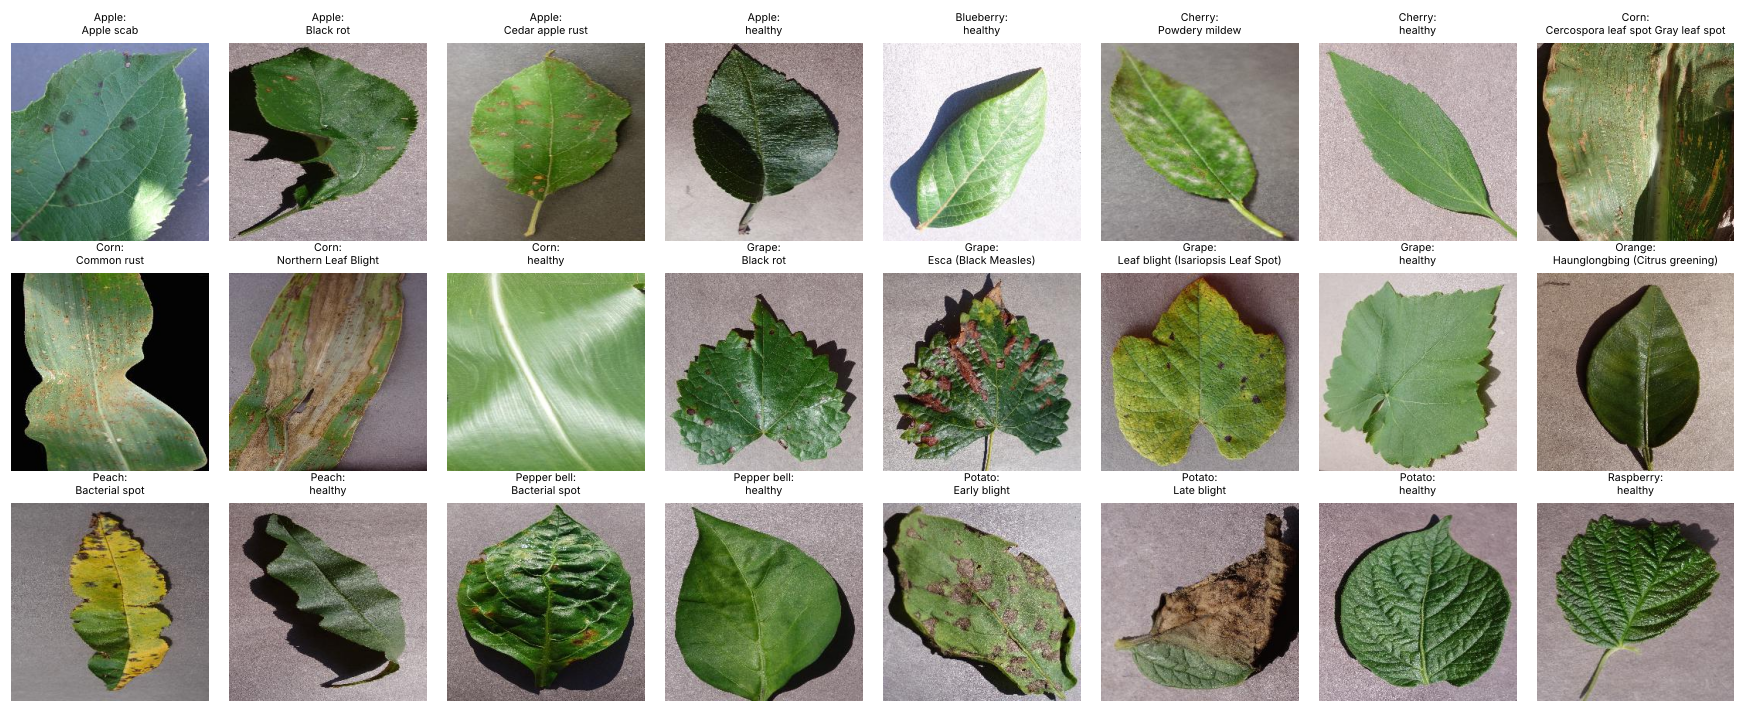

In [7]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, k in zip(axes.ravel(), range(0, 38)):
    p = df[df.label == k].path.iloc[0]
    ax.imshow(load_rgb(p) if 'load_rgb' in globals() else plt.imread(p)); ax.set_title(pretty(classes[k]).replace(': ', ':\n'), fontsize=7); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Pre-processing

### 2.1 Filters, CLAHE and synthetic degradations

```text
Stage 1 - Image preprocessing.

    resize (256x256) -> Gaussian smoothing -> bilateral filtering -> CLAHE on L*

* Gaussian low-pass filtering suppresses sensor (Gaussian-like) noise.
* The bilateral filter is an edge-preserving smoother: it averages pixels that
  are close in BOTH space and intensity, so lesion borders stay sharp.
* CLAHE (Contrast Limited Adaptive Histogram Equalisation) is applied only to
  the lightness channel L* of CIELAB, so illumination is normalised without
  shifting the chromatic channels a*/b* that carry the disease colour cues.
```

In [8]:
def load_rgb(path, size=IMG_SIZE):
    """Read an image from disk as an RGB uint8 array of shape (size, size, 3)."""
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise IOError(f"cannot read {path}")
    if bgr.shape[:2] != (size, size):
        bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def gaussian(rgb):
    return cv2.GaussianBlur(rgb, (GAUSS_KSIZE, GAUSS_KSIZE), GAUSS_SIGMA)


def bilateral(rgb):
    return cv2.bilateralFilter(rgb, BILATERAL_D, BILATERAL_SIGMA_COLOR, BILATERAL_SIGMA_SPACE)


def clahe_lab(rgb):
    """CLAHE on the L* channel of CIELAB only."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE)
    lab[..., 0] = clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def preprocess(rgb, return_stages=False):
    """Full preprocessing chain. Returns the enhanced RGB image (and stages if asked)."""
    g = gaussian(rgb)
    b = bilateral(g)
    c = clahe_lab(b)
    if return_stages:
        return c, {"Original": rgb, "Gaussian": g, "Bilateral": b, "CLAHE (L*)": c}
    return c


# --------------------------------------------------------------------------
# Synthetic degradations used for the robustness experiment
# --------------------------------------------------------------------------
def add_gaussian_noise(rgb, sigma=20, seed=0):
    rng = np.random.default_rng(seed)
    noisy = rgb.astype(np.float32) + rng.normal(0, sigma, rgb.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def darken(rgb, gamma=2.2, gain=0.6):
    """Under-exposure: gamma > 1 compresses mid-tones, gain scales intensity down."""
    x = (rgb.astype(np.float32) / 255.0) ** gamma * gain
    return np.clip(x * 255, 0, 255).astype(np.uint8)


def blur(rgb, k=7):
    return cv2.GaussianBlur(rgb, (k, k), 0)


def uneven_illumination(rgb, strength=0.6):
    """Linear left-to-right illumination gradient (shadow on one side)."""
    h, w = rgb.shape[:2]
    ramp = np.linspace(1.0 - strength, 1.0, w, dtype=np.float32)[None, :, None]
    return np.clip(rgb.astype(np.float32) * ramp, 0, 255).astype(np.uint8)


DEGRADATIONS = {
    "Clean": lambda x: x,
    "Gaussian noise (sigma=20)": add_gaussian_noise,
    "Gaussian blur (7x7)": blur,
    "Low light (gamma=2.2)": darken,
    "Uneven illumination": uneven_illumination,
}

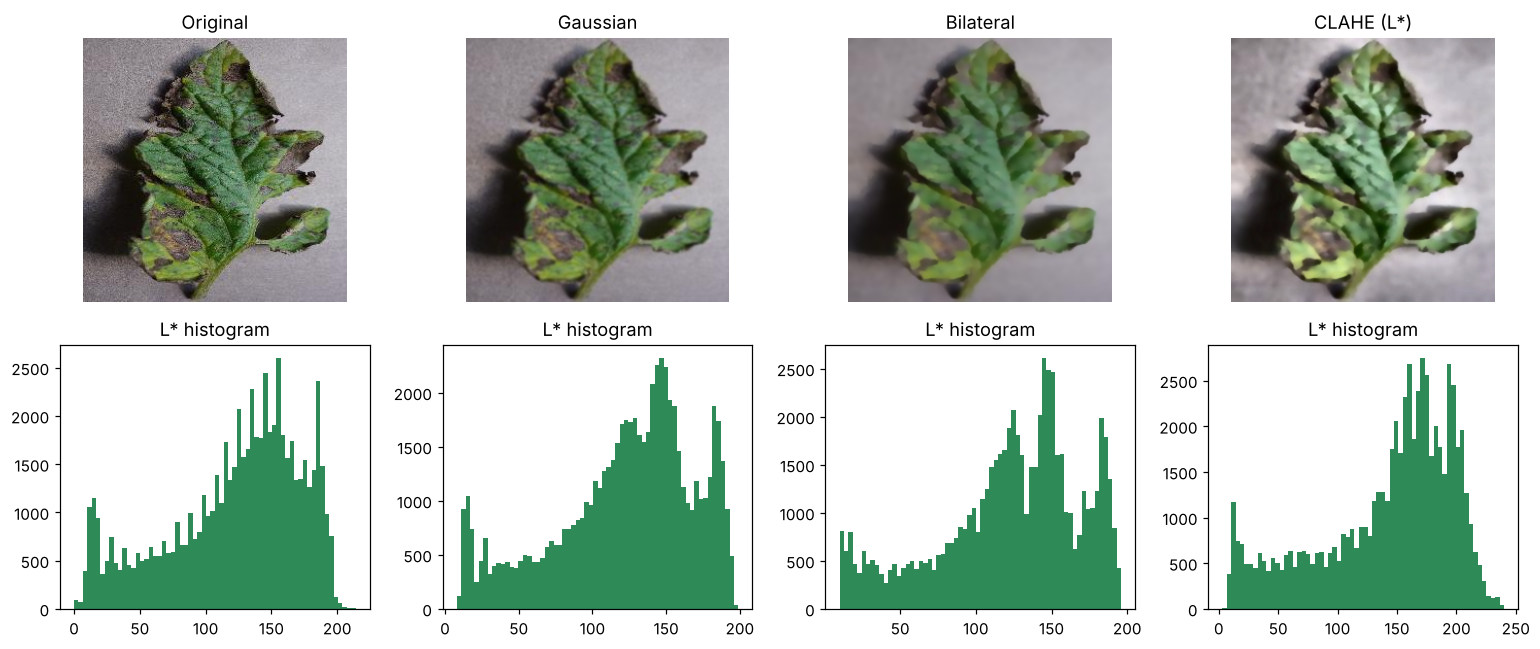

In [9]:
sample = df[df['class'] == 'Tomato___Early_blight'].sort_values('path').path.iloc[5]
img = load_rgb(sample)
out, stages = preprocess(img, return_stages=True)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i, (name, im) in enumerate(stages.items()):
    axes[0, i].imshow(im); axes[0, i].set_title(name); axes[0, i].axis('off')
    axes[1, i].hist(cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[..., 0].ravel(), 64, color='seagreen'); axes[1, i].set_title('L* histogram')
plt.tight_layout(); plt.show()

## 3. Colour-space segmentation and morphology

### 3.1 Leaf mask, lesion mask, morphology and IoU/Dice

```text
Stage 2 - Colour-space segmentation and morphology.

Two masks are produced for every leaf image:

1. LEAF mask (leaf vs. background)
   - Otsu thresholding of the HSV saturation channel (background paper is grey,
     i.e. low saturation; leaf tissue - healthy or diseased - is chromatic), OR
   - K-means (k=3) clustering of the CIELAB chromaticity plane (a*, b*), where
     the cluster with the lowest chroma sqrt(a*^2 + b*^2) is background.
   - Proposed: K-means on (a*, b*) followed by morphological closing/opening,
     largest-connected-component selection and hole filling. (Ablations: Otsu,
     Otsu/K-means fusion and GrabCut refinement were also evaluated.)

2. LESION mask (diseased vs. healthy tissue, inside the leaf)
   - K-means (k=3) on (a*, b*) of leaf pixels only; the cluster whose centre is
     least green (largest a*) is the lesion candidate.
   - It is accepted only where the pixel is genuinely non-green: a* above an
     Otsu threshold computed on the leaf's a* values AND hue outside the
     healthy-green band, or very dark necrotic tissue.
   - Morphological opening removes speckle; closing fills gaps inside spots.
```

In [10]:
_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (MORPH_KERNEL, MORPH_KERNEL))
_CRITERIA = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)


def _kmeans(samples, k):
    cv2.setRNGSeed(SEED)
    _, labels, centres = cv2.kmeans(samples.astype(np.float32), k, None, _CRITERIA, 3, cv2.KMEANS_PP_CENTERS)
    return labels.ravel(), centres


def _largest_component(mask):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), 8)
    if n <= 1:
        return mask.astype(bool)
    keep = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return lab == keep


def clean_mask(mask, largest=True, fill=True):
    """Morphological closing then opening, keep the largest blob, fill holes."""
    m = mask.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, _KERNEL, iterations=2)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, _KERNEL, iterations=1)
    m = m.astype(bool)
    if largest:
        m = _largest_component(m)
    if fill:
        m = ndi.binary_fill_holes(m)
    return m


# ------------------------------------------------------------------ leaf mask
def leaf_mask_otsu(rgb):
    """Otsu threshold on HSV saturation (raw, no post-processing)."""
    s = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1]
    _, m = cv2.threshold(s, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m.astype(bool)


def _is_leaf_colour(centres, min_b=4.0, min_chroma=6.0):
    """Leaf tissue (green, yellow or brown) lies in the b* > 0 half-plane of
    CIELAB and is chromatic; grey, blue or purple backgrounds and cast shadows
    are either achromatic or have b* <= 0."""
    a, b = centres[:, 0], centres[:, 1]
    return (b > min_b) & (np.hypot(a, b) > min_chroma)


def leaf_mask_kmeans(rgb, k=KMEANS_K):
    """K-means on (a*, b*); clusters with a leaf-like chromaticity are kept (raw)."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float32)
    ab = lab[:, 1:] - 128.0
    labels, centres = _kmeans(ab, k)
    keep = _is_leaf_colour(centres)
    if not keep.any():                      # fallback: drop the least chromatic cluster
        keep = np.ones(k, bool)
        keep[np.argmin(np.hypot(centres[:, 0], centres[:, 1]))] = False
    return keep[labels].reshape(rgb.shape[:2])


def leaf_mask(rgb):
    """Proposed leaf segmentation: K-means on Lab chromaticity + morphology."""
    return clean_mask(leaf_mask_kmeans(rgb))


def leaf_mask_fusion(rgb):
    """Ablation: union of the Otsu-S and K-means cues, then morphology."""
    return clean_mask(leaf_mask_otsu(rgb) | leaf_mask_kmeans(rgb))


def leaf_mask_grabcut(rgb, band=15):
    """Ablation: GrabCut refinement initialised from the proposed mask."""
    m = leaf_mask(rgb)
    k = np.ones((band, band), np.uint8)
    inner = cv2.erode(m.astype(np.uint8), k) > 0
    outer = cv2.dilate(m.astype(np.uint8), k) > 0
    gc = np.full(m.shape, cv2.GC_BGD, np.uint8)
    gc[outer] = cv2.GC_PR_BGD
    gc[m] = cv2.GC_PR_FGD
    gc[inner] = cv2.GC_FGD
    try:
        cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), gc, None,
                    np.zeros((1, 65)), np.zeros((1, 65)), 3, cv2.GC_INIT_WITH_MASK)
    except cv2.error:          # leaf fills the whole frame -> nothing to refine
        return m
    return clean_mask((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD))


LEAF_METHODS = {
    "Otsu (HSV-S)": leaf_mask_otsu,
    "Otsu + morphology": lambda x: clean_mask(leaf_mask_otsu(x)),
    "K-means (Lab a*b*)": leaf_mask_kmeans,
    "Otsu/K-means fusion + morph.": leaf_mask_fusion,
    "K-means + GrabCut": leaf_mask_grabcut,
    "K-means + morphology (proposed)": leaf_mask,
}


# ---------------------------------------------------------------- lesion mask
def lesion_mask(rgb, leaf):
    """Segment diseased tissue inside the leaf mask."""
    if leaf.sum() < 50:
        return np.zeros_like(leaf)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    a, b, L = lab[..., 1].astype(np.float32), lab[..., 2].astype(np.float32), lab[..., 0]
    h, v = hsv[..., 0], hsv[..., 2]

    idx = np.flatnonzero(leaf.ravel())
    ab = np.stack([a.ravel()[idx], b.ravel()[idx]], 1) - 128.0
    labels, centres = _kmeans(ab, KMEANS_K)
    lesion_cluster = np.argmax(centres[:, 0])            # least green centre
    cand = np.zeros(leaf.size, bool)
    cand[idx[labels == lesion_cluster]] = True
    cand = cand.reshape(leaf.shape)

    # Otsu on a* of the leaf pixels decides how "non-green" a pixel must be
    a_leaf = a[leaf].astype(np.uint8).reshape(-1, 1)
    t_a, _ = cv2.threshold(a_leaf, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    non_green_hue = (h < 25) | (h > 95)                   # OpenCV hue: green ~ 35-85
    chroma_ok = a > max(t_a, 118)                         # 128 = neutral, lower = greener
    inner = cv2.erode(leaf.astype(np.uint8), _KERNEL, iterations=3).astype(bool)
    necrotic = (v < 60) & (L < 70) & inner                # dark dead tissue, away from edge shadows
    lesion = leaf & ((cand & chroma_ok & non_green_hue) | necrotic)

    lesion = cv2.morphologyEx(lesion.astype(np.uint8), cv2.MORPH_OPEN, _KERNEL)
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_CLOSE, _KERNEL)
    return lesion.astype(bool) & leaf


def boundary(mask):
    """Morphological gradient = dilation - erosion (object contour)."""
    m = mask.astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_GRADIENT, _KERNEL).astype(bool)


# ---------------------------------------------------------------- metrics
def iou_dice(pred, ref):
    pred, ref = pred.astype(bool), ref.astype(bool)
    inter = np.logical_and(pred, ref).sum()
    union = np.logical_or(pred, ref).sum()
    s = pred.sum() + ref.sum()
    return (inter / union if union else 1.0), (2 * inter / s if s else 1.0)


def reference_leaf_mask(segmented_rgb, thr=20):
    """PlantVillage 'segmented' images have a black background -> binary mask."""
    m = segmented_rgb.max(axis=2) > thr
    return ndi.binary_fill_holes(clean_mask(m, largest=True, fill=False))

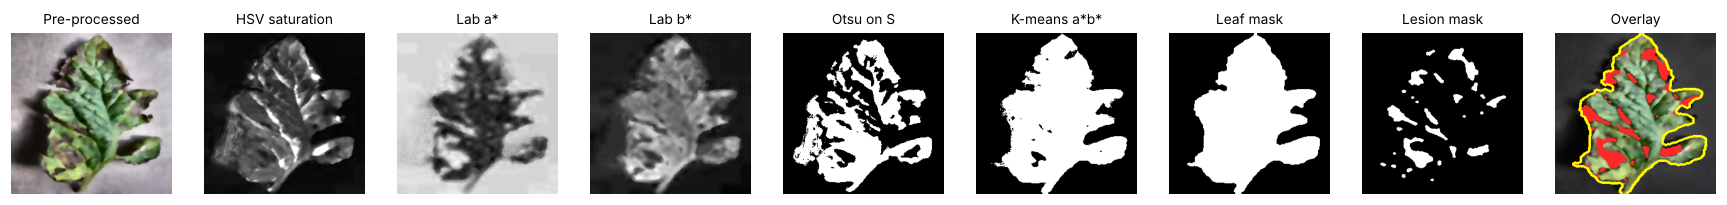

lesion area = 17.5% of the leaf


In [11]:
x = preprocess(img)
lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB); hsv = cv2.cvtColor(x, cv2.COLOR_RGB2HSV)
leaf = leaf_mask(x); les = lesion_mask(x, leaf)
ov = x.copy(); ov[~leaf] = (ov[~leaf] * .3).astype(np.uint8); ov[les] = [255, 40, 40]; ov[boundary(leaf)] = [255, 255, 0]
panels = [('Pre-processed', x), ('HSV saturation', hsv[..., 1]), ('Lab a*', lab[..., 1]), ('Lab b*', lab[..., 2]),
          ('Otsu on S', leaf_mask_otsu(x)), ('K-means a*b*', leaf_mask_kmeans(x)), ('Leaf mask', leaf), ('Lesion mask', les), ('Overlay', ov)]
fig, axes = plt.subplots(1, 9, figsize=(20, 2.8))
for ax, (t, im) in zip(axes, panels):
    ax.imshow(im, cmap=None if im.ndim == 3 else 'gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.show()
print(f'lesion area = {les.sum() / leaf.sum():.1%} of the leaf')

### 3.2 Quantitative segmentation evaluation

```text
Quantitative evaluation of leaf segmentation (IoU and Dice) against the
background-removed "segmented" version of PlantVillage, plus a lesion-ratio
analysis (healthy vs. diseased leaves).

Outputs
  results/tables/segmentation_iou.csv        per image / per method scores
  results/tables/segmentation_summary.json   mean / median / std per method
  results/tables/lesion_ratio.csv            lesion area ratio for every test image
```

In [12]:
def pairs():
    for seg in sorted(glob.glob(os.path.join(glob.escape(SEGMENTED_DIR), "*", "*"))):
        cls = os.path.basename(os.path.dirname(seg))
        stem = os.path.basename(seg).replace("_final_masked.jpg", "")
        hits = glob.glob(os.path.join(glob.escape(COLOR_DIR), glob.escape(cls), glob.escape(stem) + ".*"))
        if hits:
            yield cls, hits[0], seg


def run_segmentation_evaluation():
    rows = []
    for cls, colour, seg in pairs():
        ref = reference_leaf_mask(load_rgb(seg))
        raw = load_rgb(colour)
        pre = preprocess(raw)
        for inp_name, img in (("raw", raw), ("preprocessed", pre)):
            for name, fn in LEAF_METHODS.items():
                t = time.time()
                m = fn(img)
                ms = 1000 * (time.time() - t)
                iou, dice = iou_dice(m, ref)
                rows.append({"class": cls, "image": os.path.basename(colour), "input": inp_name,
                             "method": name, "iou": iou, "dice": dice, "ms": ms})
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(TABLE_DIR, "segmentation_iou.csv"), index=False)
    summary = (df.groupby(["input", "method"])
                 .agg(iou_mean=("iou", "mean"), iou_median=("iou", "median"), iou_std=("iou", "std"),
                      dice_mean=("dice", "mean"), dice_median=("dice", "median"), ms_mean=("ms", "mean"),
                      n=("iou", "size"))
                 .reset_index())
    summary.to_csv(os.path.join(TABLE_DIR, "segmentation_summary.csv"), index=False)
    print(summary.to_string(index=False))

    # lesion area ratio on the test split (healthy vs. diseased)
    split, _ = get_split(save=False)
    te = split[split.split == "test"]
    lr = []
    for p, c in zip(te.path, te["class"]):
        x = preprocess(load_rgb(p))
        leaf = leaf_mask(x)
        les = lesion_mask(x, leaf)
        lr.append({"class": c, "healthy": "healthy" in c.lower(), "lesion_ratio": les.sum() / max(leaf.sum(), 1)})
    lr = pd.DataFrame(lr)
    lr.to_csv(os.path.join(TABLE_DIR, "lesion_ratio.csv"), index=False)
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(~lr.healthy, lr.lesion_ratio)
    stats = {"healthy_median": float(lr[lr.healthy].lesion_ratio.median()),
             "diseased_median": float(lr[~lr.healthy].lesion_ratio.median()),
             "auc_lesion_ratio_healthy_vs_diseased": float(auc), "n": int(len(lr))}
    with open(os.path.join(TABLE_DIR, "lesion_ratio_summary.json"), "w") as f:
        json.dump(stats, f, indent=1)
    print(stats)

In [13]:
if RECOMPUTE_SEG_EVAL or not os.path.exists(os.path.join(TABLE_DIR, 'segmentation_iou.csv')):
    run_segmentation_evaluation()
seg = pd.read_csv(os.path.join(TABLE_DIR, 'segmentation_iou.csv'))
seg.groupby(['input', 'method'])[['iou', 'dice', 'ms']].mean().round(4)

iou    dice       ms
input        method                                                  
preprocessed K-means (Lab a*b*)               0.9164  0.9474   9.6916
             K-means + GrabCut                0.9056  0.9409  63.2943
             K-means + morphology (proposed)  0.9203  0.9487  11.5702
             Otsu (HSV-S)                     0.6902  0.7922   0.1372
             Otsu + morphology                0.7216  0.8029   1.9202
             Otsu/K-means fusion + morph.     0.9027  0.9421  11.5060
raw          K-means (Lab a*b*)               0.9115  0.9441   9.8654
             K-means + GrabCut                0.9036  0.9391  70.5645
             K-means + morphology (proposed)  0.9200  0.9479  11.6244
             Otsu (HSV-S)                     0.6944  0.7963   0.1229
             Otsu + morphology                0.8035  0.8733   1.8987
             Otsu/K-means fusion + morph.     0.9006  0.9414  11.6154

In [14]:
json.load(open(os.path.join(TABLE_DIR, 'lesion_ratio_summary.json')))

{'healthy_median': 0.015957526612664343,
 'diseased_median': 0.07119130303487846,
 'auc_lesion_ratio_healthy_vs_diseased': 0.7080525255332453,
 'n': 1685}

## 4. Feature extraction

### 4.1 Colour, texture (GLCM + LBP), shape and HOG features

```text
Stage 3 - Hand-crafted feature extraction.

For each preprocessed leaf image we compute four feature groups:

  COLOUR  (78)  colour moments (mean, std, skewness) of the leaf region in RGB,
                HSV and CIELAB (27) + the same moments of the lesion region (27)
                + a 16-bin hue histogram and 8-bin a* histogram of the leaf (24)
  TEXTURE (64)  GLCM on the grey leaf region: contrast, dissimilarity,
                homogeneity, energy, correlation, ASM at distances {1, 2, 4}
                (mean and range over 0/45/90/135 degrees) = 36, plus a uniform
                LBP (P=8, R=1) histogram (10) and LBP (P=16, R=2) histogram (18)
  SHAPE   (8)   lesion area ratio, number of lesion blobs, mean / max blob area,
                leaf solidity, Canny edge density inside the leaf, lesion
                boundary length ratio, leaf area ratio
  HOG     (1764) Histogram of Oriented Gradients on a 128x128 grey image
                (9 orientations, 16x16 cells, 2x2 blocks)
```

In [15]:
warnings.filterwarnings("ignore", category=RuntimeWarning)

GLCM_PROPS = ("contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM")
GLCM_DIST = (1, 2, 4)
GLCM_ANGLES = (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)


def _moments(pixels):
    """Mean, standard deviation and skewness of each channel (N x C -> 3C)."""
    if len(pixels) < 3:
        return np.zeros(pixels.shape[1] * 3, np.float32)
    p = pixels.astype(np.float32)
    sk = np.nan_to_num(skew(p, axis=0))
    return np.concatenate([p.mean(0), p.std(0), sk])


def colour_features(rgb, leaf, lesion):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    stack = np.concatenate([rgb, hsv, lab], axis=2)              # H x W x 9
    f_leaf = _moments(stack[leaf])
    f_les = _moments(stack[lesion]) if lesion.sum() >= 3 else np.zeros(27, np.float32)
    hue_hist = np.histogram(hsv[..., 0][leaf], bins=16, range=(0, 180))[0]
    a_hist = np.histogram(lab[..., 1][leaf], bins=8, range=(96, 176))[0]
    n = max(leaf.sum(), 1)
    return np.concatenate([f_leaf, f_les, hue_hist / n, a_hist / n])


def texture_features(grey, leaf):
    # GLCM on a 64-level quantised grey image; background set to level 0 and
    # the (0, *) / (*, 0) co-occurrences removed so only leaf texture counts.
    q = (grey.astype(np.float32) / 256 * 63).astype(np.uint8) + 1
    q[~leaf] = 0
    glcm = graycomatrix(q, GLCM_DIST, GLCM_ANGLES, levels=64, symmetric=True, normed=False).astype(np.float64)
    glcm[0, :, :, :] = 0
    glcm[:, 0, :, :] = 0
    glcm /= np.maximum(glcm.sum(axis=(0, 1), keepdims=True), 1)
    glcm_f = []
    for prop in GLCM_PROPS:
        v = np.nan_to_num(graycoprops(glcm, prop))               # dist x angle
        glcm_f += [v.mean(1), v.max(1) - v.min(1)]
    glcm_f = np.concatenate(glcm_f)                              # 6 props x 3 dist x 2 = 36

    lbp_f = []
    for P, R in ((8, 1), (16, 2)):
        lbp = local_binary_pattern(grey, P, R, "uniform")
        h = np.histogram(lbp[leaf], bins=P + 2, range=(0, P + 2))[0].astype(np.float32)
        lbp_f.append(h / max(h.sum(), 1))
    return np.concatenate([glcm_f] + lbp_f)


def shape_features(grey, leaf, lesion):
    n_leaf = max(leaf.sum(), 1)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(lesion.astype(np.uint8), 8)
    areas = stats[1:, cv2.CC_STAT_AREA] / n_leaf if n > 1 else np.zeros(1)
    cnts, _ = cv2.findContours(leaf.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    solidity = 0.0
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        hull = cv2.contourArea(cv2.convexHull(c))
        solidity = cv2.contourArea(c) / hull if hull > 0 else 0.0
    edges = cv2.Canny(grey, 50, 150) > 0
    return np.array([
        lesion.sum() / n_leaf,                 # lesion area ratio
        n - 1,                                 # number of lesion blobs
        areas.mean(), areas.max(),
        solidity,
        edges[leaf].mean() if leaf.any() else 0.0,
        boundary(lesion).sum() / n_leaf,
        leaf.mean(),
    ], np.float32)


def hog_features(grey):
    g = cv2.resize(grey, (HOG_SIZE, HOG_SIZE), interpolation=cv2.INTER_AREA)
    return hog(g, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True).astype(np.float32)


def extract_all(rgb, apply_preprocessing=True, use_mask=True):
    """Return a dict {group_name: vector} for one RGB image.

    apply_preprocessing / use_mask switch the corresponding stage off for the
    ablation study (without a mask the whole image is treated as leaf).
    """
    x = preprocess(rgb) if apply_preprocessing else rgb
    if use_mask:
        leaf = leaf_mask(x)
        if leaf.sum() < 0.02 * leaf.size:      # degenerate mask -> use whole frame
            leaf = np.ones(x.shape[:2], bool)
    else:
        leaf = np.ones(x.shape[:2], bool)
    lesion = lesion_mask(x, leaf)
    grey = cv2.cvtColor(x, cv2.COLOR_RGB2GRAY)
    return {
        "colour": colour_features(x, leaf, lesion).astype(np.float32),
        "texture": texture_features(grey, leaf).astype(np.float32),
        "shape": shape_features(grey, leaf, lesion),
        "hog": hog_features(grey),
    }


FEATURE_GROUPS = ("colour", "texture", "shape", "hog")

In [16]:
f = extract_all(img)
{k: v.shape for k, v in f.items()}

{'colour': (78,), 'texture': (64,), 'shape': (8,), 'hog': (1764,)}

### 4.2 Feature extraction for all images (cached)

```text
Extract hand-crafted features for every image and cache them to data/cache/.

Configurations
  full      preprocessing ON,  leaf mask ON   (proposed pipeline)
  no_pre    preprocessing OFF, leaf mask ON   (ablation)
  no_mask   preprocessing ON,  leaf mask OFF  (ablation)
  robust_*  test images corrupted by a degradation, with and without preprocessing

Usage:  python scripts/extract_features.py [--workers 2]
```

In [17]:
def _job(args):
    path, pre, mask, degr = args
    img = load_rgb(path)
    if degr:
        img = DEGRADATIONS[degr](img)
    d = extract_all(img, apply_preprocessing=pre, use_mask=mask)
    return [d[g] for g in FEATURE_GROUPS]


def run(name, paths, labels, pre, mask, degr, workers):
    out = os.path.join(CACHE_DIR, f"feat_{name}.npz")
    if os.path.exists(out):
        print(f"[skip] {name}")
        return
    t = time.time()
    with Pool(workers) as pool:
        res = pool.map(_job, [(p, pre, mask, degr) for p in paths], chunksize=16)
    arrays = {g: np.stack([r[i] for r in res]) for i, g in enumerate(FEATURE_GROUPS)}
    np.savez_compressed(out, labels=np.asarray(labels), **arrays)
    dt = time.time() - t
    print(f"[done] {name}: {len(paths)} images in {dt:.0f}s ({1000 * dt / len(paths):.1f} ms/img)", flush=True)


def run_feature_extraction(workers=2):
    a = argparse.Namespace(workers=workers)
    df, _ = get_split()
    paths, labels = df["path"].tolist(), df["label"].tolist()
    run("full", paths, labels, True, True, None, a.workers)
    run("no_pre", paths, labels, False, True, None, a.workers)
    run("no_mask", paths, labels, True, False, None, a.workers)

    test = df[df["split"] == "test"]
    for degr in DEGRADATIONS:
        if degr == "Clean":
            continue
        tag = degr.split(" (")[0].lower().replace(" ", "_")
        run(f"robust_{tag}_pre", test["path"].tolist(), test["label"].tolist(), True, True, degr, a.workers)
        run(f"robust_{tag}_nopre", test["path"].tolist(), test["label"].tolist(), False, True, degr, a.workers)

In [18]:
if RECOMPUTE_FEATURES or not os.path.exists(os.path.join(CACHE_DIR, 'feat_full.npz')):
    run_feature_extraction(workers=os.cpu_count())
z = np.load(os.path.join(CACHE_DIR, 'feat_full.npz'))
{g: z[g].shape for g in FEATURE_GROUPS}

{'colour': (11227, 78),
 'texture': (11227, 64),
 'shape': (11227, 8),
 'hog': (11227, 1764)}

## 5. Classical classifiers: SVM and Random Forest

### 5.1 Experiments E1–E3

```text
Train and evaluate the classical (hand-crafted feature) classifiers.

Experiments
  E1  feature-group study    SVM and Random Forest on each feature group and
                             their combinations (preprocessing + leaf mask ON)
  E2  pipeline ablation      best feature set with preprocessing OFF / mask OFF
  E3  robustness             clean-trained models evaluated on degraded test
                             images, with vs. without the preprocessing stage

SVM hyper-parameters (C, gamma) are selected on the validation split; the
final model is refit on train only and scored once on the held-out test split.

Usage:  python scripts/train_classical.py
```

In [19]:
FEATURE_SETS = {
    "Colour": ["colour"],
    "Texture (GLCM+LBP)": ["texture"],
    "Shape": ["shape"],
    "HOG": ["hog"],
    "Colour+Texture": ["colour", "texture"],
    "Colour+Texture+Shape": ["colour", "texture", "shape"],
    "All (C+T+S+HOG)": ["colour", "texture", "shape", "hog"],
}
DEGR_TAGS = ["gaussian_noise", "gaussian_blur", "low_light", "uneven_illumination"]


def load_features(name):
    return np.load(os.path.join(CACHE_DIR, f"feat_{name}.npz"))


def stack(z, groups):
    return np.hstack([z[g] for g in groups]).astype(np.float32)


class _PCASVC(SVC):
    """RBF-SVM whose gamma is set relative to the PCA output dimension."""

    def __init__(self, C=1.0, gamma_factor=1.0):
        super().__init__(C=C, kernel="rbf", decision_function_shape="ovr", random_state=SEED)
        self.gamma_factor = gamma_factor

    def fit(self, X, y, sample_weight=None):
        self.gamma = self.gamma_factor / (X.shape[1] * X.var())
        return super().fit(X, y, sample_weight)


def svm_pipeline(C, gamma, n_feat):
    steps = [StandardScaler()]
    if n_feat > 400:                       # PCA keeps 99% variance of the large HOG block
        steps.append(PCA(n_components=0.99, svd_solver="full", random_state=SEED))
    if isinstance(gamma, str) and gamma.startswith("pca:"):
        steps.append(_PCASVC(C=C, gamma_factor=float(gamma[4:])))
    else:
        steps.append(SVC(C=C, gamma=gamma, kernel="rbf", decision_function_shape="ovr", random_state=SEED))
    return make_pipeline(*steps)


def fit_svm(Xtr, ytr, Xva, yva):
    """Grid search on the validation split: C in {10, 30, 100}, gamma = f / d with
    f in {0.25, 0.5, 1} (d = number of input features after scaling/PCA;
    f = 1 corresponds to sklearn's gamma='scale' for standardised data)."""
    best = (-1, None)
    d = Xtr.shape[1] if Xtr.shape[1] <= 400 else None
    for C in (10, 30, 100):
        for f in (0.25, 0.5, 1.0):
            gamma = f / d if d else f"pca:{f}"
            m = svm_pipeline(C, gamma, Xtr.shape[1]).fit(Xtr, ytr)
            f = f1_score(yva, m.predict(Xva), average="macro")
            if f > best[0]:
                best = (f, (C, gamma), m)
    return best[2], {"C": best[1][0], "gamma": best[1][1], "val_macro_f1": best[0]}


def fit_rf(Xtr, ytr, Xva, yva):
    m = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
    return m, {"n_estimators": 500, "val_macro_f1": f1_score(yva, m.predict(Xva), average="macro")}


def scores(model, X):
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)


def evaluate_model(model, X, y):
    t = time.time()
    s = scores(model, X)
    ms = 1000 * (time.time() - t) / len(y)
    pred = s.argmax(1)
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            "weighted_f1": f1_score(y, pred, average="weighted"), "classify_ms_per_img": ms}, s


def run_classical_experiments():
    df, classes = get_split()
    split = df["split"].to_numpy()
    tr, va, te = split == "train", split == "val", split == "test"
    full = load_features("full")
    y = full["labels"]
    results = {"feature_groups": [], "ablation": [], "robustness": []}

    # ---------------- E1: feature-group study ---------------------------------
    best_set, best_f1, best_svm = None, -1, None
    for name, groups in FEATURE_SETS.items():
        X = stack(full, groups)
        for clf_name, fitter in (("SVM (RBF)", fit_svm), ("Random Forest", fit_rf)):
            t = time.time()
            m, hp = fitter(X[tr], y[tr], X[va], y[va])
            fit_s = time.time() - t
            met, s = evaluate_model(m, X[te], y[te])
            row = {"features": name, "dims": X.shape[1], "classifier": clf_name, **met, **hp, "fit_seconds": fit_s}
            results["feature_groups"].append(row)
            print(json.dumps(row), flush=True)
            np.savez_compressed(os.path.join(CACHE_DIR, f"pred_{clf_name.split()[0].lower()}_{name}.npz"),
                                y=y[te], s=s)
            if clf_name.startswith("SVM") and met["macro_f1"] > best_f1:
                best_set, best_f1, best_svm = name, met["macro_f1"], m
    joblib.dump(best_svm, os.path.join(MODEL_DIR, "svm_best.joblib"), compress=3)

    groups = FEATURE_SETS[best_set]
    best_hp = next(r for r in results["feature_groups"] if r["features"] == best_set and r["classifier"] == "SVM (RBF)")
    C, G = best_hp["C"], best_hp["gamma"]

    # ---------------- E2: ablation of preprocessing and leaf mask ------------
    trained = {"full": best_svm}
    for cfg, label in (("full", "Full pipeline (pre-processing + leaf mask)"),
                       ("no_pre", "Without pre-processing"),
                       ("no_mask", "Without leaf segmentation mask")):
        z = load_features(cfg)
        X = stack(z, groups)
        m = trained.get(cfg) or svm_pipeline(C, G, X.shape[1]).fit(X[tr], y[tr])
        trained[cfg] = m
        met, _ = evaluate_model(m, X[te], y[te])
        row = {"setting": label, "features": best_set, **met}
        results["ablation"].append(row)
        print(json.dumps(row), flush=True)

    # ---------------- E3: robustness to image degradations -------------------
    Xte_full = stack(full, groups)[te]
    Xte_nopre = stack(load_features("no_pre"), groups)[te]
    for tag, Xp, Xn in [("clean", Xte_full, Xte_nopre)] + [
            (t, stack(load_features(f"robust_{t}_pre"), groups), stack(load_features(f"robust_{t}_nopre"), groups)) for t in DEGR_TAGS]:
        for prep, X, m in (("with pre-processing", Xp, trained["full"]), ("without pre-processing", Xn, trained["no_pre"])):
            met, _ = evaluate_model(m, X, y[te])
            row = {"degradation": tag, "pipeline": prep, **met}
            results["robustness"].append(row)
            print(json.dumps(row), flush=True)

    results["best_feature_set"] = best_set
    with open(os.path.join(TABLE_DIR, "classical_results.json"), "w") as f:
        json.dump(results, f, indent=1)

In [20]:
res_path = os.path.join(TABLE_DIR, 'classical_results.json')
if RETRAIN_CLASSICAL or not os.path.exists(res_path):
    run_classical_experiments()
res = json.load(open(res_path))
pd.DataFrame(res['feature_groups'])[['features', 'dims', 'classifier', 'accuracy', 'macro_f1', 'weighted_f1']].round(4)

,features,dims,classifier,accuracy,macro_f1,weighted_f1
0,Colour,78,SVM (RBF),0.8172,0.8147,0.8171
1,Colour,78,Random Forest,0.7501,0.7439,0.7464
2,Texture (GLCM+LBP),64,SVM (RBF),0.7139,0.7154,0.7151
3,Texture (GLCM+LBP),64,Random Forest,0.5976,0.5867,0.5863
4,Shape,8,SVM (RBF),0.4944,0.4828,0.4843
5,Shape,8,Random Forest,0.4718,0.4593,0.4599
6,HOG,1764,SVM (RBF),0.6985,0.6977,0.6966
7,HOG,1764,Random Forest,0.5579,0.5293,0.5314
8,Colour+Texture,142,SVM (RBF),0.8902,0.8890,0.8898
9,Colour+Texture,142,Random Forest,0.8445,0.8413,0.8425


In [21]:
print('Best feature set:', res['best_feature_set'])
pd.DataFrame(res['ablation'])[['setting', 'accuracy', 'macro_f1']].round(4)

Best feature set: Colour+Texture+Shape


,setting,accuracy,macro_f1
0,Full pipeline (pre-processing + leaf mask),0.9074,0.9076
1,Without pre-processing,0.9092,0.9100
2,Without leaf segmentation mask,0.9466,0.9471


## 6. MobileNetV2 transfer learning

### 6.1 MobileNetV2 architecture

```text
MobileNetV2 (Sandler et al., CVPR 2018) in PyTorch.

Architecture definition follows the layout of the open-source implementation
at https://github.com/d-li14/mobilenetv2.pytorch (Apache-2.0), so that its
ImageNet-pretrained weights (pretrained/mobilenetv2_1.0-0c6065bc.pth,
72.19% top-1) can be loaded directly. Weights are loaded with
torch.load(weights_only=True), i.e. as plain tensors only.
```

In [22]:
def _make_divisible(v, divisor, min_value=None):
    min_value = min_value or divisor
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


def _conv_bn(inp, oup, k, stride):
    return nn.Sequential(nn.Conv2d(inp, oup, k, stride, k // 2, bias=False),
                         nn.BatchNorm2d(oup), nn.ReLU6(inplace=True))


class InvertedResidual(nn.Module):
    """Inverted residual block: 1x1 expand -> 3x3 depthwise -> 1x1 linear projection."""

    def __init__(self, inp, oup, stride, expand_ratio):
        super().__init__()
        hidden = round(inp * expand_ratio)
        self.identity = stride == 1 and inp == oup
        layers = []
        if expand_ratio != 1:
            layers += [nn.Conv2d(inp, hidden, 1, 1, 0, bias=False), nn.BatchNorm2d(hidden), nn.ReLU6(inplace=True)]
        layers += [nn.Conv2d(hidden, hidden, 3, stride, 1, groups=hidden, bias=False), nn.BatchNorm2d(hidden),
                   nn.ReLU6(inplace=True),
                   nn.Conv2d(hidden, oup, 1, 1, 0, bias=False), nn.BatchNorm2d(oup)]
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.conv(x) if self.identity else self.conv(x)


class MobileNetV2(nn.Module):
    CFGS = [  # t (expansion), c (channels), n (repeats), s (stride)
        [1, 16, 1, 1], [6, 24, 2, 2], [6, 32, 3, 2], [6, 64, 4, 2],
        [6, 96, 3, 1], [6, 160, 3, 2], [6, 320, 1, 1]]

    def __init__(self, num_classes=1000, width_mult=1.0):
        super().__init__()
        inp = _make_divisible(32 * width_mult, 8)
        layers = [_conv_bn(3, inp, 3, 2)]
        for t, c, n, s in self.CFGS:
            out = _make_divisible(c * width_mult, 8)
            for i in range(n):
                layers.append(InvertedResidual(inp, out, s if i == 0 else 1, t))
                inp = out
        self.features = nn.Sequential(*layers)
        last = _make_divisible(1280 * width_mult, 8) if width_mult > 1.0 else 1280
        self.conv = _conv_bn(inp, last, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(last, num_classes)
        self._init_weights()

    def forward(self, x):
        x = self.avgpool(self.conv(self.features(x))).flatten(1)
        return self.classifier(x)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2.0 / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()
            elif isinstance(m, nn.Linear):
                m.weight.data.normal_(0, 0.01)
                m.bias.data.zero_()


def build_mobilenetv2(num_classes, pretrained_path=None, dropout=0.2):
    """MobileNetV2 with ImageNet weights and a new classification head."""
    model = MobileNetV2(1000)
    if pretrained_path:
        state = torch.load(pretrained_path, map_location="cpu", weights_only=True)
        model.load_state_dict(state)
    model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(1280, num_classes))
    return model

### 6.2 Data pipeline, fine-tuning loop and inference

```text
Stage 4b - Deep-learning benchmark: transfer learning with MobileNetV2.

The ImageNet-pretrained MobileNetV2 backbone is fine-tuned end-to-end on the
same stratified split used by the classical models.

Training recipe
  * input 224x224, ImageNet normalisation
  * augmentation: random resized crop (0.7-1.0), horizontal + vertical flip,
    rotation (+-20 deg), colour jitter (brightness/contrast/saturation 0.2)
  * AdamW (lr 1e-3 head / 3e-4 backbone, weight decay 1e-4), cosine schedule
    with 1 warm-up epoch, label smoothing 0.1, batch 32
  * the checkpoint with the best validation macro-F1 is kept
```

In [23]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

TRAIN_TF = T.Compose([
    T.RandomResizedCrop(CNN_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(), T.Normalize(MEAN, STD)])
EVAL_TF = T.Compose([T.Resize((CNN_SIZE, CNN_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])


class LeafDataset(Dataset):
    def __init__(self, paths, labels, tf, degrade=None):
        self.paths, self.labels, self.tf, self.degrade = list(paths), list(labels), tf, degrade

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB").resize((256, 256))
        if self.degrade is not None:
            img = Image.fromarray(self.degrade(np.asarray(img)))
        return self.tf(img), self.labels[i]


# Fast training input path: images are decoded once into a uint8 memory-mapped
# array (N x 3 x 256 x 256) and augmented as tensors with torchvision.transforms.v2.
TRAIN_TF_T = v2.Compose([
    v2.RandomResizedCrop(CNN_SIZE, scale=(0.7, 1.0), antialias=True),
    v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), v2.RandomRotation(20),
    v2.ColorJitter(0.2, 0.2, 0.2),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])
EVAL_TF_T = v2.Compose([v2.Resize((CNN_SIZE, CNN_SIZE), antialias=True),
                        v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])


def image_cache(paths, name):
    """Decode images once into data/cache/<name>.u8 (memory-mapped uint8, CHW)."""
    from config import CACHE_DIR
    f = os.path.join(CACHE_DIR, f"{name}_{len(paths)}.u8")
    shape = (len(paths), 3, 256, 256)
    if not os.path.exists(f):
        mm = np.lib.format.open_memmap(f + ".tmp.npy", mode="w+", dtype=np.uint8, shape=shape)
        for i, p in enumerate(paths):
            mm[i] = np.asarray(Image.open(p).convert("RGB").resize((256, 256))).transpose(2, 0, 1)
        mm.flush()
        del mm
        os.replace(f + ".tmp.npy", f)
    return np.load(f, mmap_mode="r") if f.endswith(".npy") else np.lib.format.open_memmap(f, mode="r")


class CachedDataset(Dataset):
    def __init__(self, arr, labels, tf):
        self.arr, self.labels, self.tf = arr, list(labels), tf

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.tf(torch.from_numpy(np.array(self.arr[i]))), self.labels[i]


def _loader(paths, labels, tf, shuffle, degrade=None, bs=32, workers=1):
    return DataLoader(LeafDataset(paths, labels, tf, degrade), batch_size=bs, shuffle=shuffle,
                      num_workers=workers, persistent_workers=workers > 0)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(x), 1).numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(probs)


def train(df, num_classes, epochs=10, out_name="mobilenetv2_best.pt", log=print):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    torch.set_num_threads(os.cpu_count())
    tr, va = df[df.split == "train"], df[df.split == "val"]
    tl = DataLoader(CachedDataset(image_cache(list(tr.path), "train"), tr.label, TRAIN_TF_T),
                    batch_size=32, shuffle=True, num_workers=0)
    vl = DataLoader(CachedDataset(image_cache(list(va.path), "val"), va.label, EVAL_TF_T),
                    batch_size=64, shuffle=False, num_workers=0)

    model = build_mobilenetv2(num_classes, PRETRAINED_MNV2)
    head = list(model.classifier.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": backbone, "lr": 3e-4}, {"params": head, "lr": 1e-3}], weight_decay=1e-4)
    steps = epochs * len(tl)
    warm = len(tl)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, steps - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)

    history, best, start = [], -1.0, 1
    path = os.path.join(MODEL_DIR, out_name)
    resume = os.path.join(MODEL_DIR, "cnn_resume_state.pt")
    if os.path.exists(resume):  # continue an interrupted run
        st = torch.load(resume, map_location="cpu", weights_only=False)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        sched.load_state_dict(st["sched"])
        history, best, start = st["history"], st["best"], st["epoch"] + 1
        torch.set_rng_state(st["rng"])
        log(f"resumed after epoch {st['epoch']}")
    for ep in range(start, epochs + 1):
        model.train()
        t, tot, correct, n = time.time(), 0.0, 0, 0
        for x, y in tl:
            opt.zero_grad()
            out = model(x)
            loss = crit(out, y)
            loss.backward()
            opt.step()
            sched.step()
            tot += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
            if (n // len(y)) % 50 == 0:
                log(f"  epoch {ep} batch {n // len(y)}/{len(tl)} loss {tot / n:.4f} acc {correct / n:.4f}")
        yv, pv = predict(model, vl)
        val_loss = float(nn.functional.nll_loss(torch.log(torch.tensor(pv) + 1e-9), torch.tensor(yv)))
        val_acc = float((pv.argmax(1) == yv).mean())
        val_f1 = float(f1_score(yv, pv.argmax(1), average="macro"))
        rec = {"epoch": ep, "train_loss": tot / n, "train_acc": correct / n, "val_loss": val_loss,
               "val_acc": val_acc, "val_f1": val_f1, "seconds": time.time() - t}
        history.append(rec)
        log(json.dumps(rec))
        if val_f1 > best:
            best = val_f1
            torch.save(model.state_dict(), path)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "history": history, "best": best, "epoch": ep, "rng": torch.get_rng_state()}, resume + ".tmp")
        os.replace(resume + ".tmp", resume)
    if os.path.exists(resume):
        os.remove(resume)
    return history, path


def load_trained(num_classes, path):
    model = build_mobilenetv2(num_classes, None)
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    return model.eval()

### 6.3 Training and evaluation on clean and degraded test images

```text
Fine-tune MobileNetV2 and evaluate it on the clean and degraded test sets.

Outputs
  models/mobilenetv2_best.pt          best checkpoint (validation macro-F1)
  results/tables/cnn_history.json     per-epoch training log
  data/cache/pred_cnn_<setting>.npz   test-set labels and class probabilities

Usage:  python scripts/train_cnn.py --epochs 8
```

In [24]:
def run_cnn_experiment(epochs=8, skip_train=False):
    a = argparse.Namespace(epochs=epochs, skip_train=skip_train)
    df, classes = get_split()
    ckpt = os.path.join(MODEL_DIR, "mobilenetv2_best.pt")

    if not a.skip_train:
        hist, ckpt = train(df, len(classes), epochs=a.epochs, log=lambda s: print(s, flush=True))
        with open(os.path.join(TABLE_DIR, "cnn_history.json"), "w") as f:
            json.dump(hist, f, indent=1)

    model = load_trained(len(classes), ckpt)
    te = df[df.split == "test"]
    for name, fn in DEGRADATIONS.items():
        tag = "clean" if name == "Clean" else name.split(" (")[0].lower().replace(" ", "_")
        loader = _loader(te.path, te.label, EVAL_TF, False, degrade=None if name == "Clean" else fn)
        t = time.time()
        y, p = predict(model, loader)
        ms = 1000 * (time.time() - t) / len(y)
        np.savez_compressed(os.path.join(CACHE_DIR, f"pred_cnn_{tag}.npz"), y=y, p=p, ms=ms)
        print(f"{name}: acc={np.mean(p.argmax(1) == y):.4f}  ({ms:.1f} ms/img incl. loading)", flush=True)

    # pure model latency (batch of 1, no data loading)
    torch.set_num_threads(1)
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        for _ in range(5):
            model(x)
        t = time.time()
        for _ in range(50):
            model(x)
    lat = 1000 * (time.time() - t) / 50
    size_mb = os.path.getsize(ckpt) / 1e6
    n_params = sum(p.numel() for p in model.parameters())
    with open(os.path.join(TABLE_DIR, "cnn_efficiency.json"), "w") as f:
        json.dump({"latency_ms_per_image_1thread": lat, "checkpoint_mb": size_mb, "parameters": n_params}, f, indent=1)
    print(f"latency {lat:.1f} ms/img, {size_mb:.1f} MB, {n_params} params")

In [25]:
if RETRAIN_CNN or not os.path.exists(os.path.join(MODEL_DIR, 'mobilenetv2_best.pt')):
    run_cnn_experiment(epochs=8)
hist = pd.DataFrame(json.load(open(os.path.join(TABLE_DIR, 'cnn_history.json'))))
hist.round(4)

,epoch,train_loss,train_acc,val_loss,val_acc,val_f1,seconds
0,1,1.9240,0.6427,0.2990,0.9442,0.9445,419.1367
1,2,0.9528,0.9375,0.2126,0.9650,0.9636,417.4391
2,3,0.8662,0.9679,0.1785,0.9757,0.9752,414.1034
3,4,0.8122,0.9809,0.1696,0.9846,0.9848,398.6895
4,5,0.7800,0.9901,0.1390,0.9917,0.9918,408.7561
5,6,0.7595,0.9935,0.1362,0.9923,0.9924,405.3685
6,7,0.7480,0.9939,0.1425,0.9917,0.9918,423.5359
7,8,0.7446,0.9954,0.1360,0.9923,0.9918,384.0925


## 7. Results, evaluation and figures

### 7.1 Figures and summary tables

```text
Generate every figure and summary table used in the paper and the slides.

Run after extract_features.py, train_classical.py, train_cnn.py and
evaluate_segmentation.py. Figures go to results/figures/, tables to
results/tables/.
```

In [26]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300,
                     "savefig.bbox": "tight"})
C_CLASSIC, C_RF, C_CNN, C_GREY = "#2a7f62", "#8fbf9f", "#c0504d", "#7f7f7f"


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name))
    plt.close(fig)
    print("saved", name)


def pick_examples(df):
    want = ["Tomato___Early_blight", "Apple___Apple_scab", "Grape___Black_rot", "Potato___healthy"]
    out = []
    for c in want:
        sub = df[df["class"] == c].sort_values("path")
        out.append(sub.path.iloc[5])
    return out


# ------------------------------------------------------------------ figures
def fig_dataset(df, classes):
    counts = df.groupby(["class", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
    counts.index = [pretty(c) for c in counts.index]
    fig, ax = plt.subplots(figsize=(7.2, 6.4))
    counts.plot.barh(stacked=True, ax=ax, color=[C_CLASSIC, C_RF, C_CNN], width=0.8)
    ax.set_xlabel("Number of images")
    ax.invert_yaxis()
    ax.legend(["Train (70%)", "Validation (15%)", "Test (15%)"], loc="lower right", frameon=False)
    ax.tick_params(axis="y", labelsize=6.5)
    save_fig(fig, "fig_dataset_distribution.png")

    rng = np.random.default_rng(0)
    sel = rng.choice(len(classes), 12, replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(7.2, 2.8))
    for ax, k in zip(axes.ravel(), sorted(sel)):
        p = df[df.label == k].path.iloc[0]
        ax.imshow(load_rgb(p))
        ax.set_title(pretty(classes[k]).replace(": ", ":\n"), fontsize=6)
        ax.axis("off")
    save_fig(fig, "fig_dataset_samples.png")


def fig_preprocessing(paths):
    img = load_rgb(paths[0])
    _, stages = preprocess(img, return_stages=True)
    fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.8))
    for ax, (name, im) in zip(axes[0], stages.items()):
        ax.imshow(im)
        ax.set_title(name)
        ax.axis("off")
    for ax, (name, im) in zip(axes[1], stages.items()):
        L = cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[..., 0]
        ax.hist(L.ravel(), 64, color=C_CLASSIC)
        ax.set_yticks([])
        ax.set_xlabel("L* intensity")
    save_fig(fig, "fig_preprocessing_stages.png")


def fig_segmentation(paths):
    cols = ["Pre-processed", "a* channel", "Otsu\n(HSV-S)", "K-means\n(a*b*)",
            "Leaf mask\n(+ morphology)", "Lesion\nmask", "Overlay"]
    fig, axes = plt.subplots(len(paths), len(cols), figsize=(7.2, 1.15 * len(paths) + 0.3))
    for r, p in enumerate(paths):
        x = preprocess(load_rgb(p))
        a = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)[..., 1]
        leaf = leaf_mask(x)
        les = lesion_mask(x, leaf)
        ov = x.copy()
        ov[~leaf] = (ov[~leaf] * 0.3).astype(np.uint8)
        ov[les] = (0.45 * ov[les] + 0.55 * np.array([255, 30, 30])).astype(np.uint8)
        ov[boundary(leaf)] = [255, 255, 0]
        ims = [x, a, leaf_mask_otsu(x), leaf_mask_kmeans(x), leaf, les, ov]
        for c, im in enumerate(ims):
            ax = axes[r, c]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
            ax.axis("off")
            if r == 0:
                ax.set_title(cols[c], fontsize=7)
    save_fig(fig, "fig_segmentation_pipeline.png")


def fig_seg_scores():
    s = pd.read_csv(os.path.join(TABLE_DIR, "segmentation_iou.csv"))
    s = s[s["input"] == "preprocessed"]
    order = s.groupby("method").iou.mean().sort_values().index
    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    data = [s[s.method == m].iou for m in order]
    bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(C_CLASSIC if "proposed" in m else "#d9d9d9")
    for i, d in enumerate(data, 1):
        ax.plot(d.mean(), i, "k^", ms=4)
    ax.set_yticks(range(1, len(order) + 1), [m.replace(" (proposed)", "\n(proposed)") for m in order], fontsize=7)
    ax.set_xlabel("IoU with PlantVillage reference mask")
    save_fig(fig, "fig_segmentation_iou.png")


def fig_lesion_ratio():
    lr = pd.read_csv(os.path.join(TABLE_DIR, "lesion_ratio.csv"))
    fig, ax = plt.subplots(figsize=(3.5, 2.3))
    bins = np.linspace(0, 0.6, 40)
    ax.hist(lr[lr.healthy].lesion_ratio.clip(0, 0.6), bins, alpha=0.7, color=C_CLASSIC, density=True, label="Healthy")
    ax.hist(lr[~lr.healthy].lesion_ratio.clip(0, 0.6), bins, alpha=0.6, color=C_CNN, density=True, label="Diseased")
    ax.set_xlabel("Segmented lesion area / leaf area")
    ax.set_ylabel("Density")
    ax.legend(frameon=False)
    save_fig(fig, "fig_lesion_ratio.png")


def fig_feature_groups(res):
    fg = pd.DataFrame(res["feature_groups"])
    piv = fg.pivot(index="features", columns="classifier", values="macro_f1")
    piv = piv.loc[[k for k in ["Shape", "Texture (GLCM+LBP)", "HOG", "Colour", "Colour+Texture",
                               "Colour+Texture+Shape", "All (C+T+S+HOG)"] if k in piv.index]]
    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    y = np.arange(len(piv))
    ax.barh(y - 0.2, piv["SVM (RBF)"] * 100, 0.4, color=C_CLASSIC, label="SVM (RBF)")
    ax.barh(y + 0.2, piv["Random Forest"] * 100, 0.4, color=C_RF, label="Random Forest")
    for yy, v in zip(y, piv["SVM (RBF)"]):
        ax.text(v * 100 + 0.5, yy - 0.2, f"{v * 100:.1f}", va="center", fontsize=6.5)
    ax.set_yticks(y, piv.index, fontsize=7)
    ax.set_xlabel("Test macro-F1 (%)")
    ax.set_xlim(0, 105)
    ax.legend(frameon=False, fontsize=7, loc="lower right")
    save_fig(fig, "fig_feature_groups.png")


def fig_training():
    h = pd.DataFrame(json.load(open(os.path.join(TABLE_DIR, "cnn_history.json"))))
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.3))
    axes[0].plot(h.epoch, h.train_loss, "o-", color=C_CLASSIC, ms=3, label="Train")
    axes[0].plot(h.epoch, h.val_loss, "s-", color=C_CNN, ms=3, label="Validation")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(frameon=False)
    axes[1].plot(h.epoch, h.train_acc * 100, "o-", color=C_CLASSIC, ms=3, label="Train accuracy")
    axes[1].plot(h.epoch, h.val_acc * 100, "s-", color=C_CNN, ms=3, label="Validation accuracy")
    axes[1].plot(h.epoch, h.val_f1 * 100, "^--", color=C_GREY, ms=3, label="Validation macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("%")
    axes[1].legend(frameon=False, fontsize=7)
    save_fig(fig, "fig_cnn_training.png")


def fig_confusion(y, pred, classes, name, title):
    cm = confusion_matrix(y, pred, labels=range(len(classes)), normalize="true")
    fig, ax = plt.subplots(figsize=(7.2, 6.6))
    im = ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
    labels = [pretty(c) for c in classes]
    ax.set_xticks(range(len(classes)), labels, rotation=90, fontsize=5.5)
    ax.set_yticks(range(len(classes)), labels, fontsize=5.5)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j] >= 0.05 and i != j:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=4.5, color="#c0504d")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
    save_fig(fig, name)


def fig_per_class(y, p_svm, p_cnn, classes, compact=False):
    f_svm = f1_score(y, p_svm, average=None, labels=range(len(classes)))
    f_cnn = f1_score(y, p_cnn, average=None, labels=range(len(classes)))
    order = np.argsort(f_svm)
    fig, ax = plt.subplots(figsize=(3.5, 6.2) if compact else (7.2, 6.0))
    yy = np.arange(len(classes))
    ax.barh(yy - 0.2, f_svm[order] * 100, 0.4, color=C_CLASSIC, label="Classical DIP + SVM")
    ax.barh(yy + 0.2, f_cnn[order] * 100, 0.4, color=C_CNN, label="MobileNetV2")
    ax.set_yticks(yy, [pretty(classes[i]).replace("Two-spotted spider mite", "").replace(" Gray leaf spot", "")
                       .replace("(Isariopsis Leaf Spot)", "").replace("(Citrus greening)", "").replace("(Black Measles)", "")
                       for i in order], fontsize=5.5 if compact else 6)
    ax.set_xlabel("Per-class F1 (%)")
    ax.set_ylim(-0.7, len(classes) - 0.3)
    ax.set_xlim(min(50, (f_svm.min() * 100) // 10 * 10), 100.5)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.4, 1.0), ncol=2, fontsize=7 if compact else 9)
    save_fig(fig, "fig_per_class_f1_col.png" if compact else "fig_per_class_f1.png")


def fig_robustness(res, compact=False):
    rob = pd.DataFrame(res["robustness"])
    cnn = []
    for tag in ["clean", "gaussian_noise", "gaussian_blur", "low_light", "uneven_illumination"]:
        z = np.load(os.path.join(CACHE_DIR, f"pred_cnn_{tag}.npz"))
        cnn.append({"degradation": tag, "pipeline": "MobileNetV2",
                    "macro_f1": f1_score(z["y"], z["p"].argmax(1), average="macro")})
    rob = pd.concat([rob, pd.DataFrame(cnn)])
    names = {"clean": "Clean", "gaussian_noise": "Gaussian\nnoise", "gaussian_blur": "Gaussian\nblur",
             "low_light": "Low\nlight", "uneven_illumination": "Uneven\nillumination"}
    piv = rob.pivot(index="degradation", columns="pipeline", values="macro_f1").loc[list(names)]
    fig, ax = plt.subplots(figsize=(3.5, 2.7) if compact else (7.2, 2.5))
    x = np.arange(len(piv))
    series = [("without pre-processing", "#d9d9d9", "Classical, no pre-processing"),
              ("with pre-processing", C_CLASSIC, "Classical, with pre-processing"),
              ("MobileNetV2", C_CNN, "MobileNetV2")]
    for i, (col, color, lab) in enumerate(series):
        ax.bar(x + (i - 1) * 0.27, piv[col] * 100, 0.27, color=color, label=lab, edgecolor="white")
        for xx, v in zip(x, piv[col]):
            ax.text(xx + (i - 1) * 0.27, v * 100 + 1, f"{v * 100:.0f}", ha="center", fontsize=5 if compact else 6)
    ax.set_xticks(x, [names[k] for k in piv.index], fontsize=6.5 if compact else 9)
    ax.set_ylabel("Test macro-F1 (%)")
    ax.set_ylim(0, 110)
    ax.legend(frameon=False, ncol=1 if compact else 3, fontsize=6.5 if compact else 7, loc="upper center",
              bbox_to_anchor=(0.5, 1.32 if compact else 1.18))
    if compact:
        save_fig(fig, "fig_robustness_col.png")
        return
    save_fig(fig, "fig_robustness.png")
    piv.to_csv(os.path.join(TABLE_DIR, "robustness_macro_f1.csv"))


def fig_degradations(path):
    img = load_rgb(path)
    fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.1))
    for c, (name, fn) in enumerate(DEGRADATIONS.items()):
        d = fn(img)
        axes[0, c].imshow(d)
        axes[0, c].set_title(name.replace(" (", "\n("), fontsize=7)
        axes[1, c].imshow(preprocess(d))
        for r in range(2):
            axes[r, c].axis("off")
    axes[0, 0].text(-30, 128, "Degraded", rotation=90, va="center", fontsize=7)
    axes[1, 0].text(-30, 128, "Pre-processed", rotation=90, va="center", fontsize=7)
    save_fig(fig, "fig_degradations.png")


def summary_table(classes, res):
    """Overall test metrics for the main models."""
    rows = []
    best = res["best_feature_set"]
    models = [(f"SVM – {best}", f"pred_svm_{best}.npz", "s"),
              (f"Random Forest – {best}", f"pred_random_{best}.npz", "s"),
              ("SVM – HOG only", "pred_svm_HOG.npz", "s"),
              ("MobileNetV2 (fine-tuned)", "pred_cnn_clean.npz", "p")]
    preds = {}
    for name, fn, key in models:
        z = np.load(os.path.join(CACHE_DIR, fn))
        y, s = z["y"], z[key]
        pred = s.argmax(1)
        prob = np.exp(s - s.max(1, keepdims=True))
        prob /= prob.sum(1, keepdims=True)
        p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
        rows.append({"Model": name, "Accuracy": np.mean(pred == y), "Precision (macro)": p,
                     "Recall (macro)": r, "F1 (macro)": f,
                     "ROC-AUC (macro OvR)": roc_auc_score(y, prob, multi_class="ovr", average="macro")})
        preds[name] = (y, pred)
    t = pd.DataFrame(rows)
    t.to_csv(os.path.join(TABLE_DIR, "main_results.csv"), index=False)
    print(t.to_string(index=False))
    for name, (y, pred) in preds.items():
        rep = classification_report(y, pred, target_names=[pretty(c) for c in classes], digits=4, zero_division=0)
        slug = "".join(ch if ch.isalnum() else "_" for ch in name.lower()).strip("_")
        with open(os.path.join(TABLE_DIR, f"classification_report_{slug}.txt"), "w") as f:
            f.write(rep)
    return preds


def make_all_figures():
    df, classes = get_split(save=False)
    res = json.load(open(os.path.join(TABLE_DIR, "classical_results.json")))
    ex = pick_examples(df)
    fig_dataset(df, classes)
    fig_preprocessing(ex)
    fig_segmentation(ex)
    fig_degradations(ex[0])
    fig_seg_scores()
    fig_lesion_ratio()
    fig_feature_groups(res)
    fig_training()
    preds = summary_table(classes, res)
    best = res["best_feature_set"]
    y, p_svm = preds[f"SVM – {best}"]
    _, p_cnn = preds["MobileNetV2 (fine-tuned)"]
    fig_confusion(y, p_svm, classes, "fig_confusion_svm.png", f"Classical pipeline (SVM, {best})")
    fig_confusion(y, p_cnn, classes, "fig_confusion_cnn.png", "MobileNetV2 (fine-tuned)")
    fig_per_class(y, p_svm, p_cnn, classes)
    fig_per_class(y, p_svm, p_cnn, classes, compact=True)
    fig_robustness(res, compact=True)
    fig_robustness(res)

In [27]:
make_all_figures()
pd.read_csv(os.path.join(TABLE_DIR, 'main_results.csv')).round(4)

saved fig_dataset_distribution.png


saved fig_dataset_samples.png


saved fig_preprocessing_stages.png


saved fig_segmentation_pipeline.png


saved fig_degradations.png
saved fig_segmentation_iou.png
saved fig_lesion_ratio.png


/tmp/ipykernel_171/1217508916.py:90: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)


... (3 outputs left out)

saved fig_confusion_cnn.png
saved fig_per_class_f1.png


saved fig_per_class_f1_col.png


saved fig_robustness_col.png
saved fig_robustness.png


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (macro OvR)
0,SVM – Colour+Texture+Shape,0.9074,0.9104,0.9069,0.9076,0.9950
1,Random Forest – Colour+Texture+Shape,0.8647,0.8658,0.8636,0.8625,0.9953
2,SVM – HOG only,0.6985,0.7034,0.6987,0.6977,0.9685
3,MobileNetV2 (fine-tuned),0.9905,0.9910,0.9906,0.9906,0.9999


### 7.2 All numbers quoted in the paper

```text
Collect every number quoted in the paper and slides into results/tables/summary_numbers.json.
```

In [28]:
TBL = lambda f: os.path.join(TABLE_DIR, f)  # noqa: E731


def collect_numbers():
    split = pd.read_csv(TBL("data_split.csv"))
    res = json.load(open(TBL("classical_results.json")))
    seg = pd.read_csv(TBL("segmentation_summary.csv"))
    main_t = pd.read_csv(TBL("main_results.csv"))
    hist = json.load(open(TBL("cnn_history.json")))
    eff = json.load(open(TBL("cnn_efficiency.json")))
    lr = json.load(open(TBL("lesion_ratio_summary.json")))
    rob = pd.read_csv(TBL("robustness_macro_f1.csv"), index_col=0)

    best_ep = max(hist, key=lambda r: r["val_f1"])
    N = {
        "n_images": int(len(split)), "n_classes": int(split["class"].nunique()),
        "n_train": int((split.split == "train").sum()), "n_val": int((split.split == "val").sum()),
        "n_test": int((split.split == "test").sum()),
        "seg": {f"{r.input}|{r.method}": {"iou": r.iou_mean, "iou_median": r.iou_median, "dice": r.dice_mean,
                                          "ms": r.ms_mean, "n": int(r.n)} for r in seg.itertuples()},
        "lesion": lr,
        "feature_groups": res["feature_groups"],
        "best_feature_set": res["best_feature_set"],
        "ablation": res["ablation"],
        "robustness": rob.reset_index().to_dict(orient="records"),
        "main": main_t.to_dict(orient="records"),
        "cnn": {"epochs": len(hist), "best_epoch": best_ep["epoch"], "best_val_f1": best_ep["val_f1"],
                "minutes": sum(r["seconds"] for r in hist) / 60, **eff},
    }
    with open(TBL("summary_numbers.json"), "w") as f:
        json.dump(N, f, indent=1, default=float)
    print(json.dumps({k: N[k] for k in ("n_images", "n_train", "n_val", "n_test", "best_feature_set")}))
    print(main_t.round(4).to_string(index=False))

In [29]:
collect_numbers()

{"n_images": 11227, "n_train": 7858, "n_val": 1684, "n_test": 1685, "best_feature_set": "Colour+Texture+Shape"}
                               Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  ROC-AUC (macro OvR)
          SVM – Colour+Texture+Shape    0.9074             0.9104          0.9069      0.9076               0.9950
Random Forest – Colour+Texture+Shape    0.8647             0.8658          0.8636      0.8625               0.9953
                      SVM – HOG only    0.6985             0.7034          0.6987      0.6977               0.9685
            MobileNetV2 (fine-tuned)    0.9905             0.9910          0.9906      0.9906               0.9999


fig_dataset_distribution.png


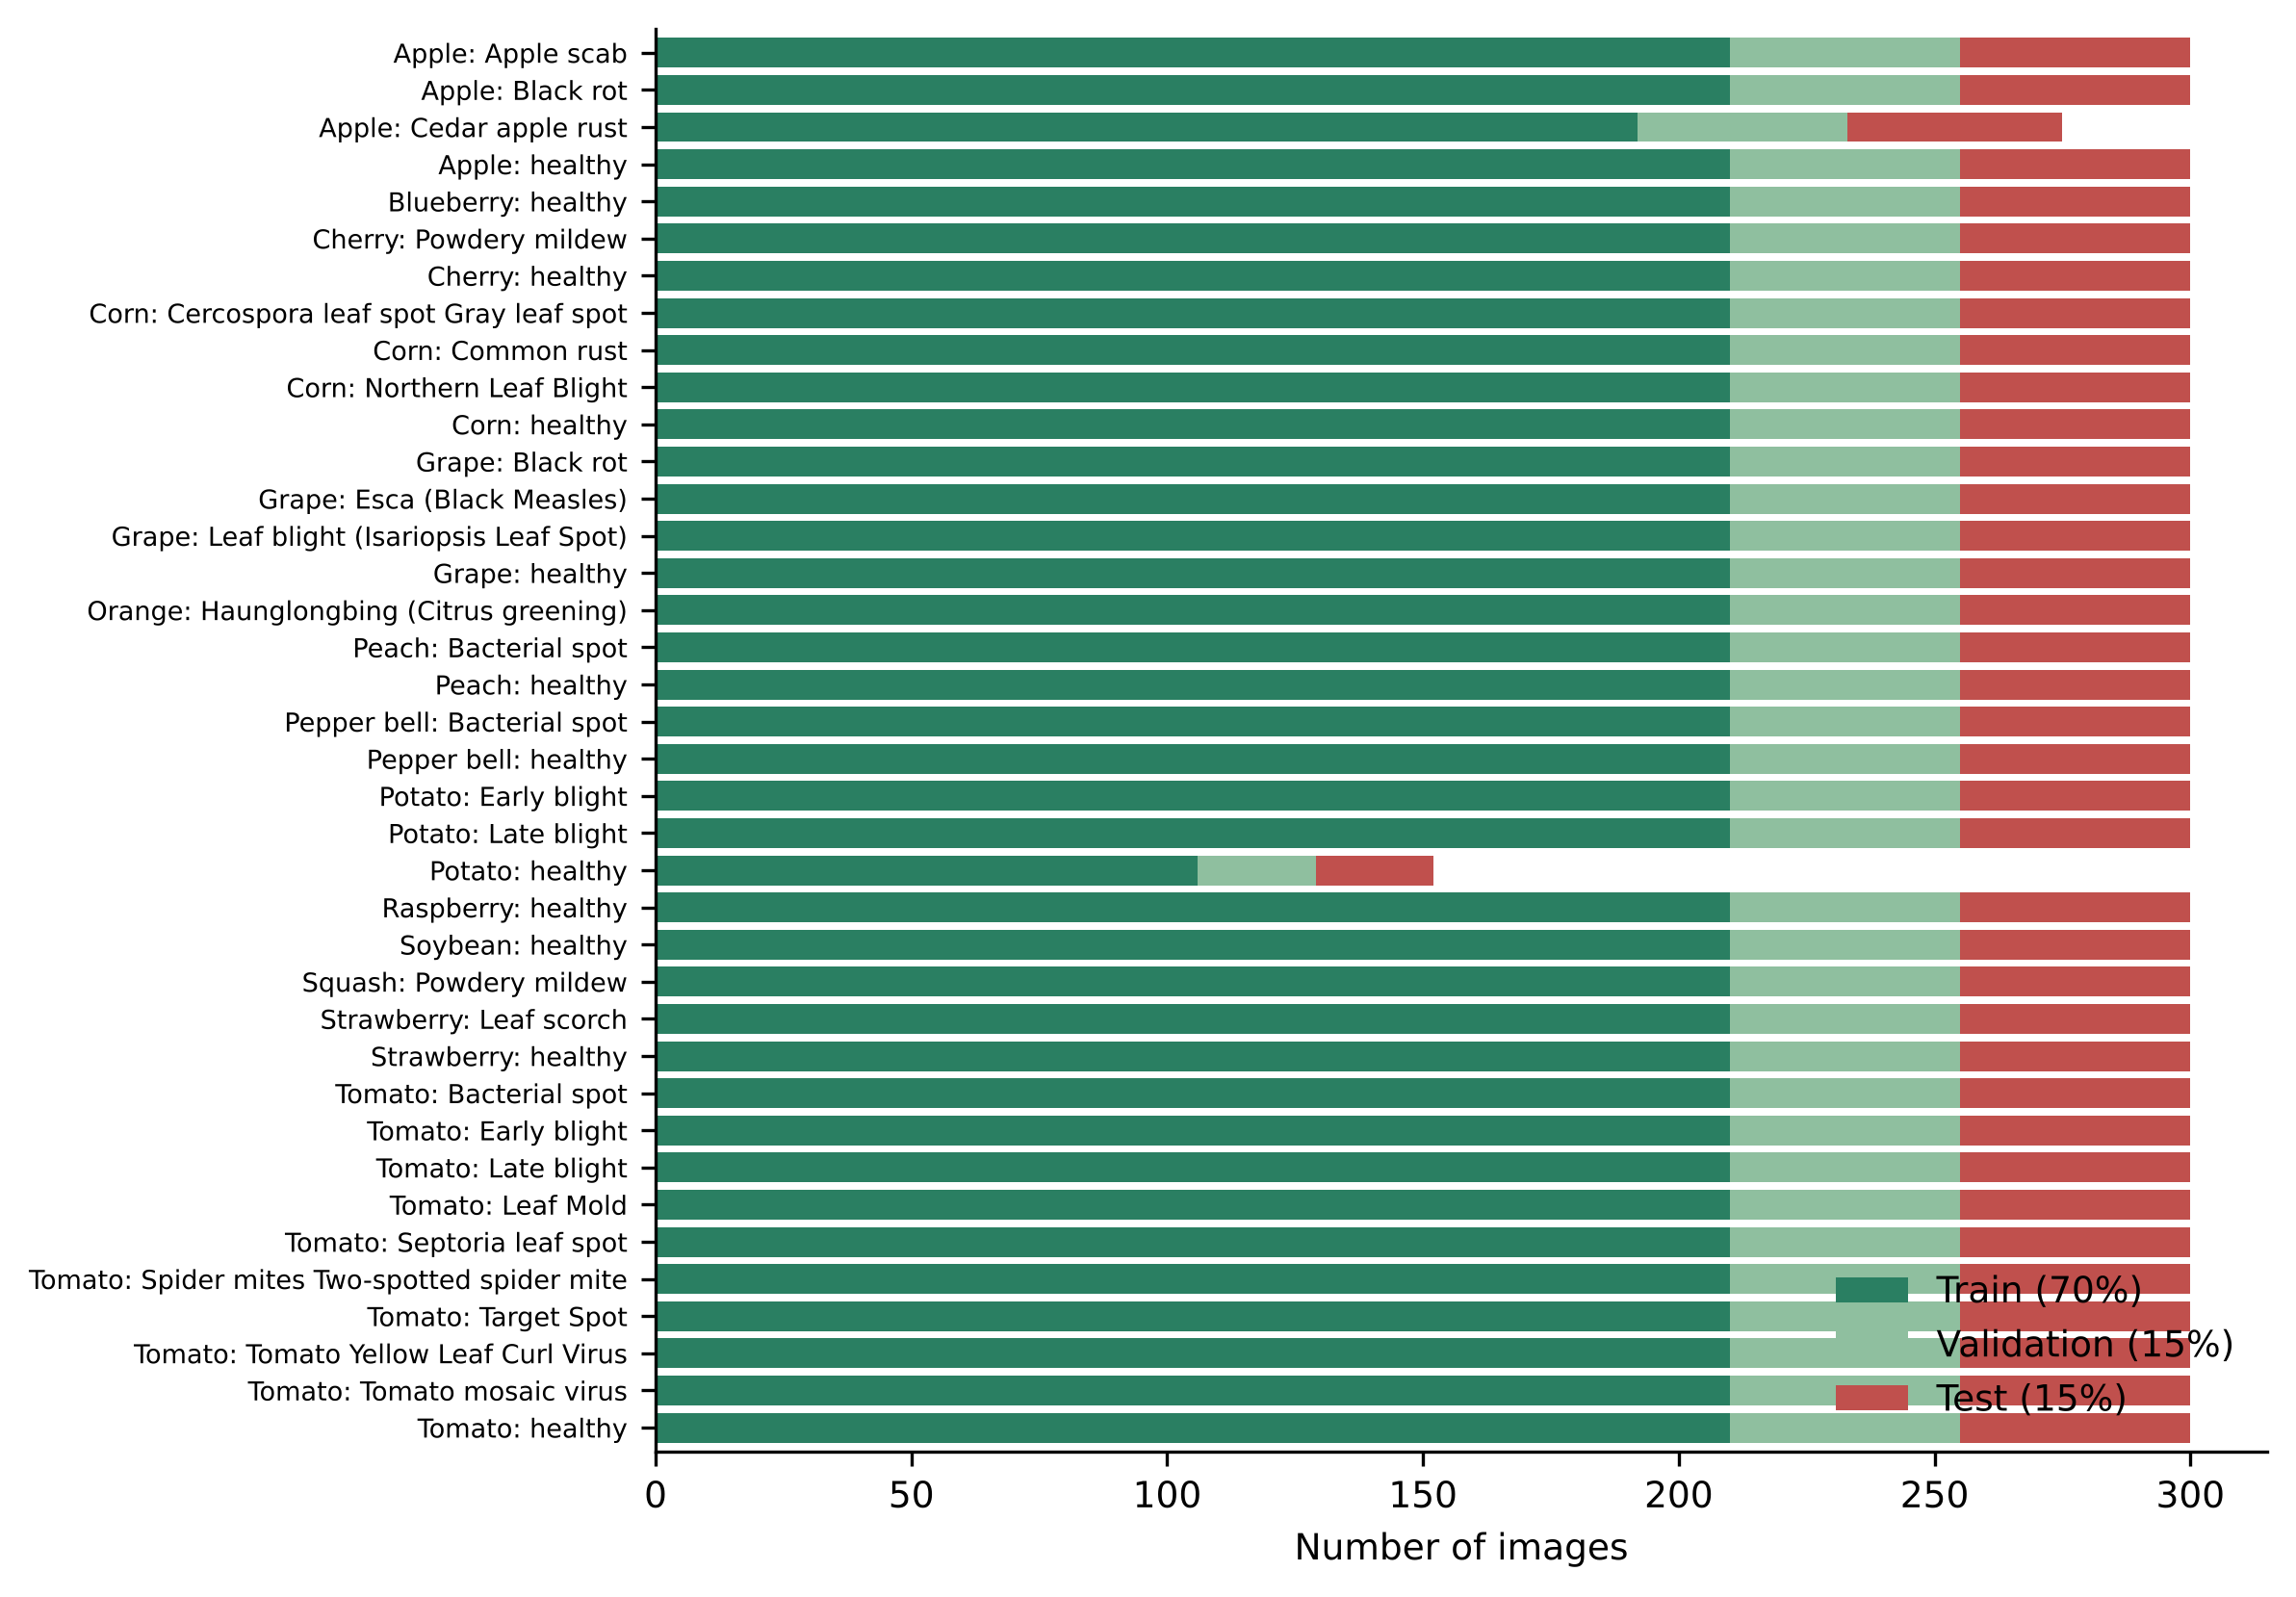

fig_segmentation_pipeline.png


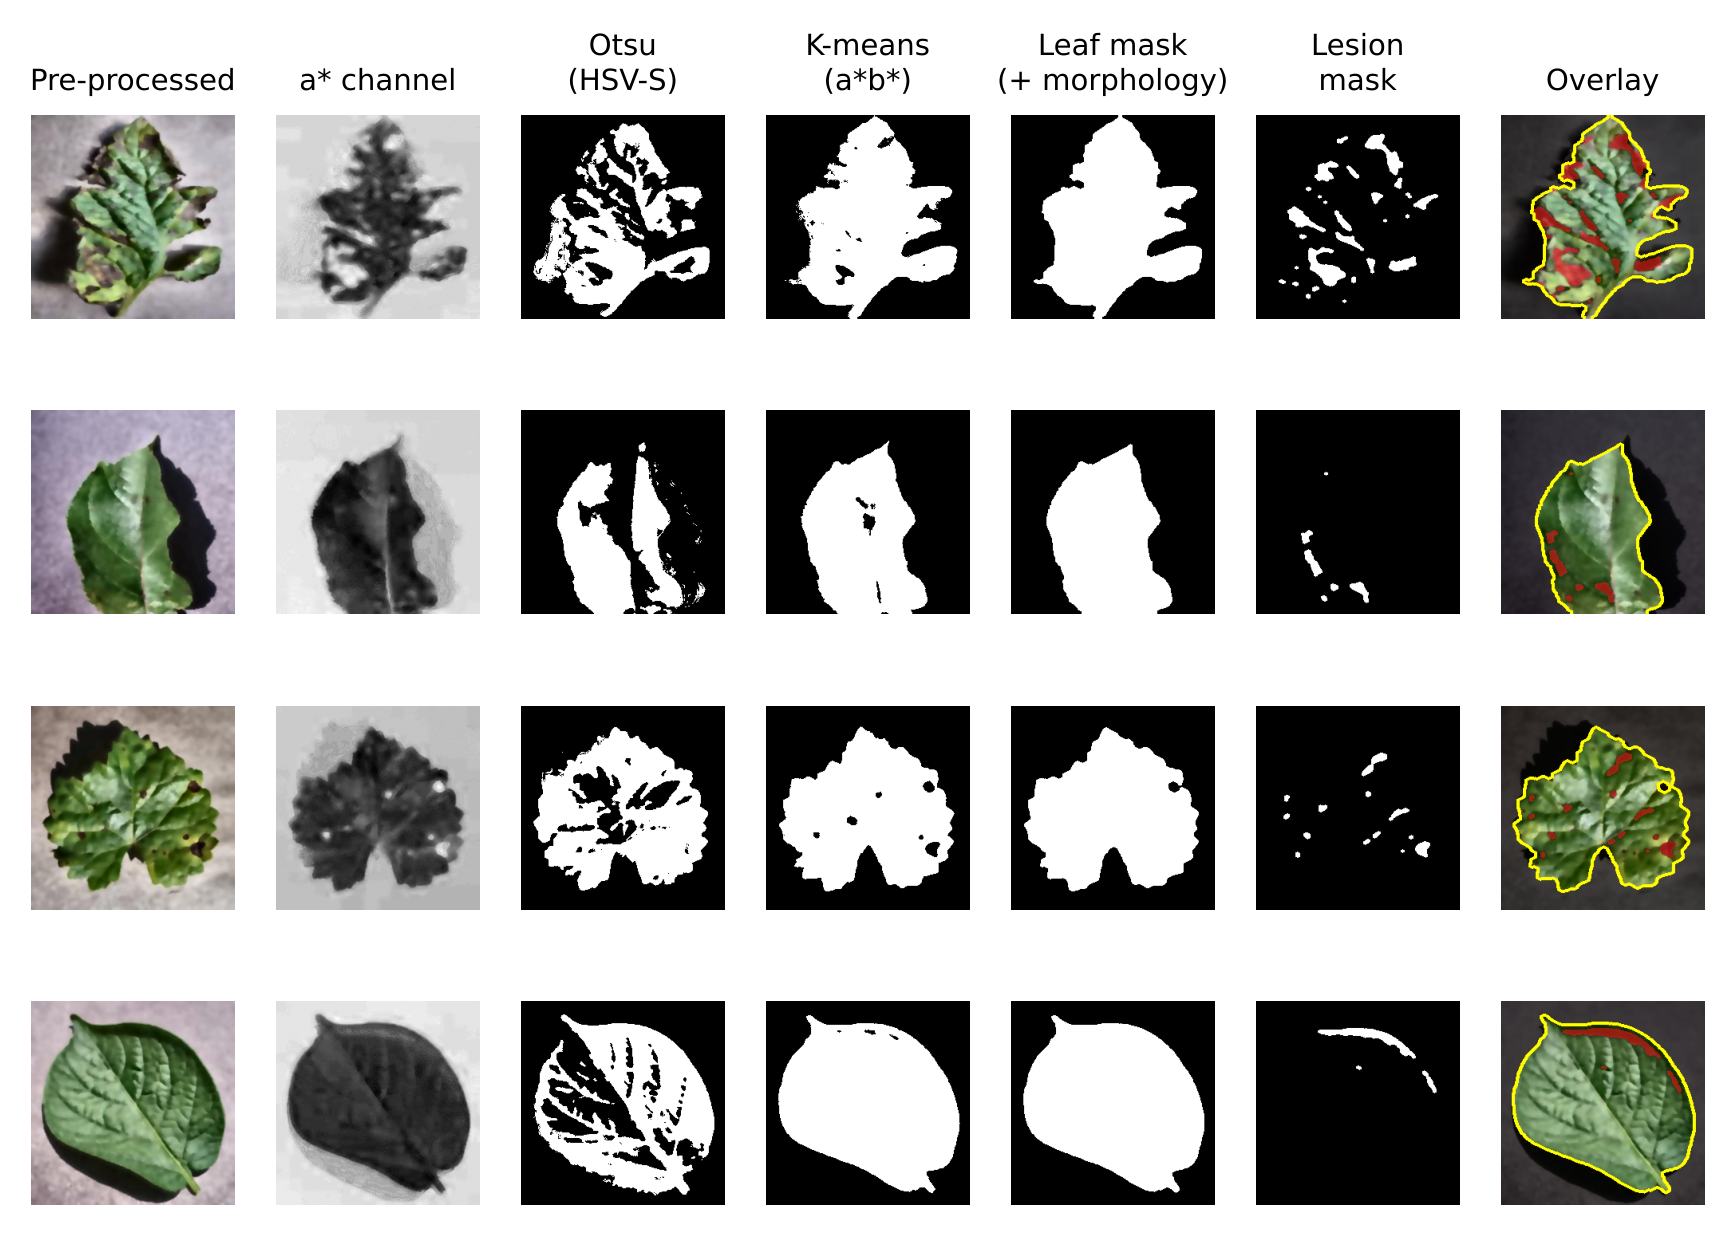

fig_segmentation_iou.png


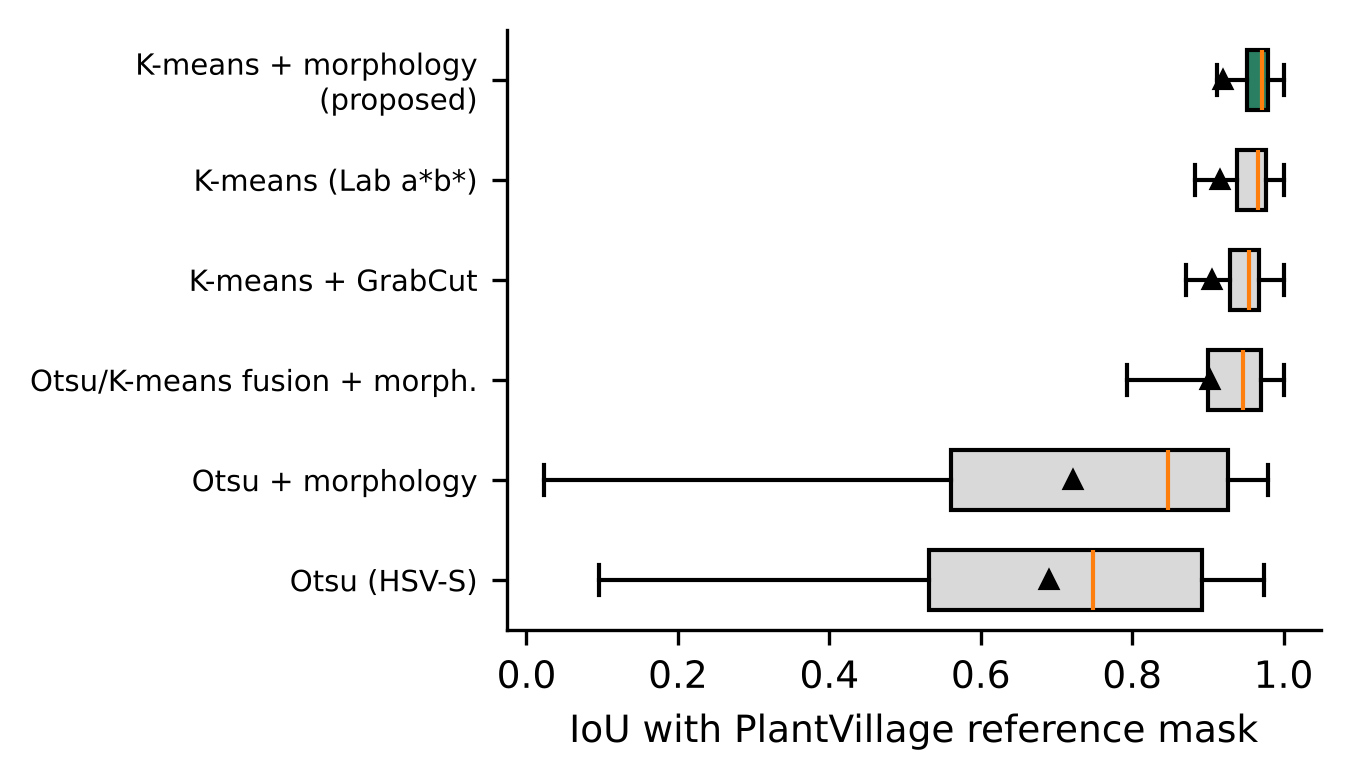

fig_lesion_ratio.png


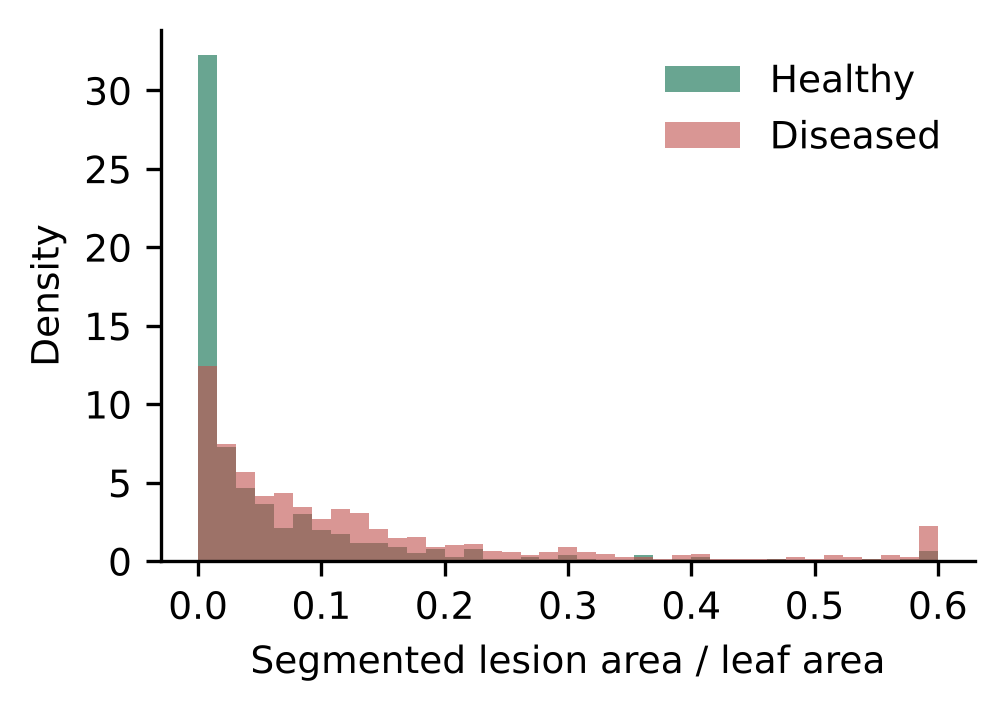

fig_feature_groups.png


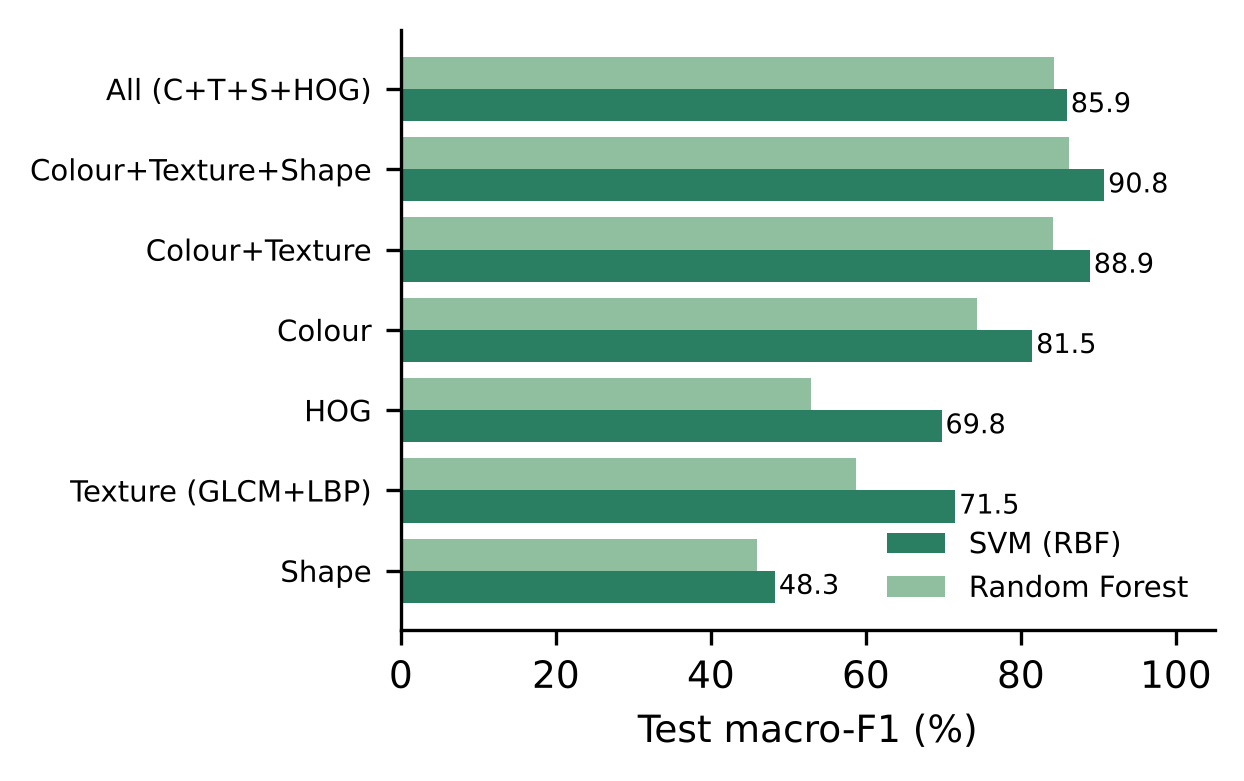

fig_cnn_training.png


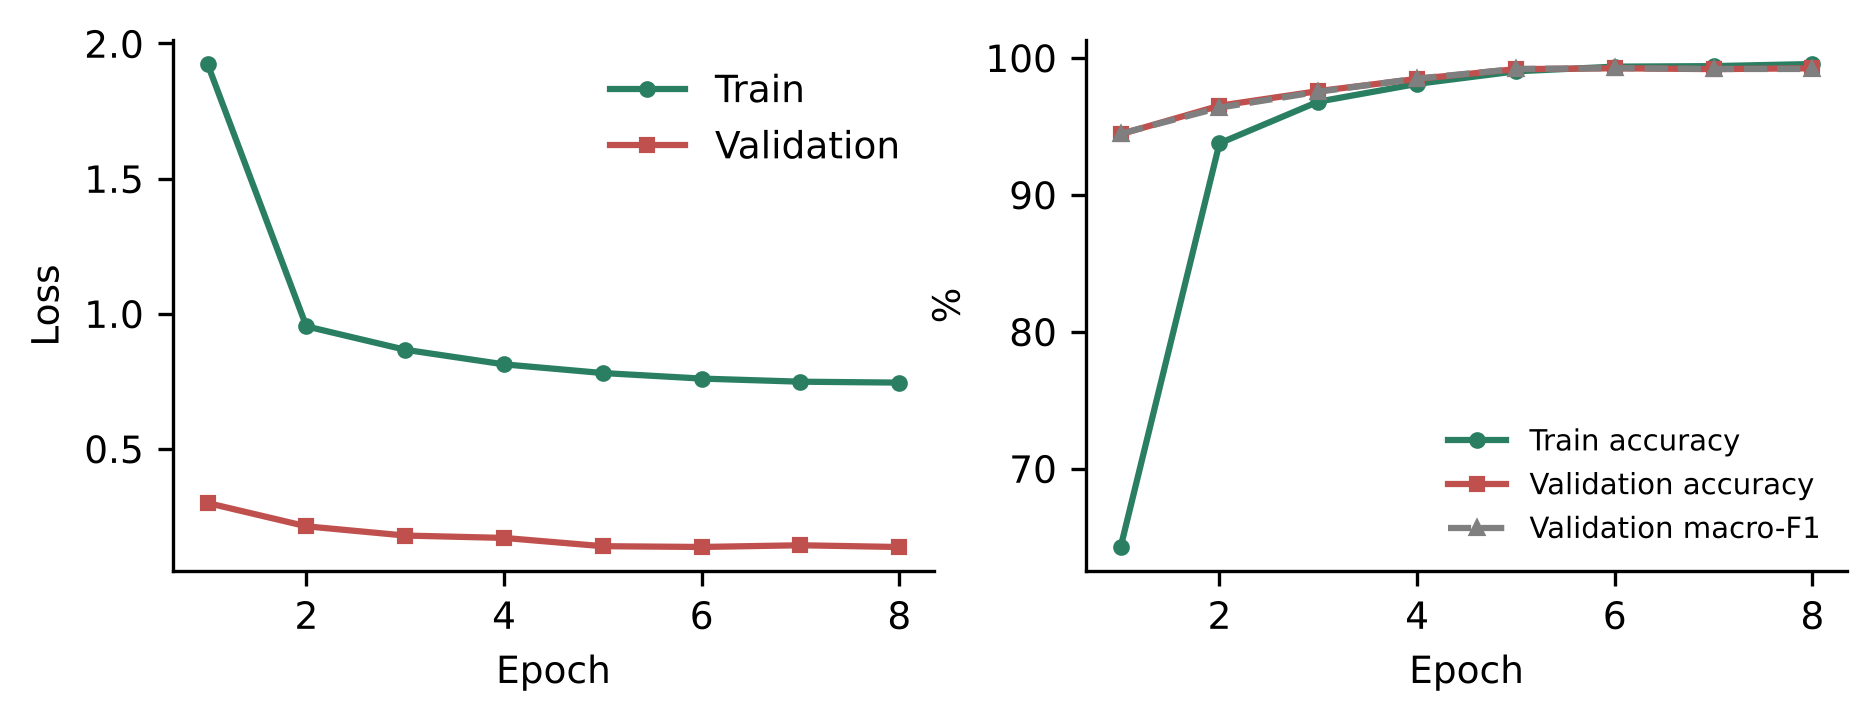

fig_per_class_f1.png


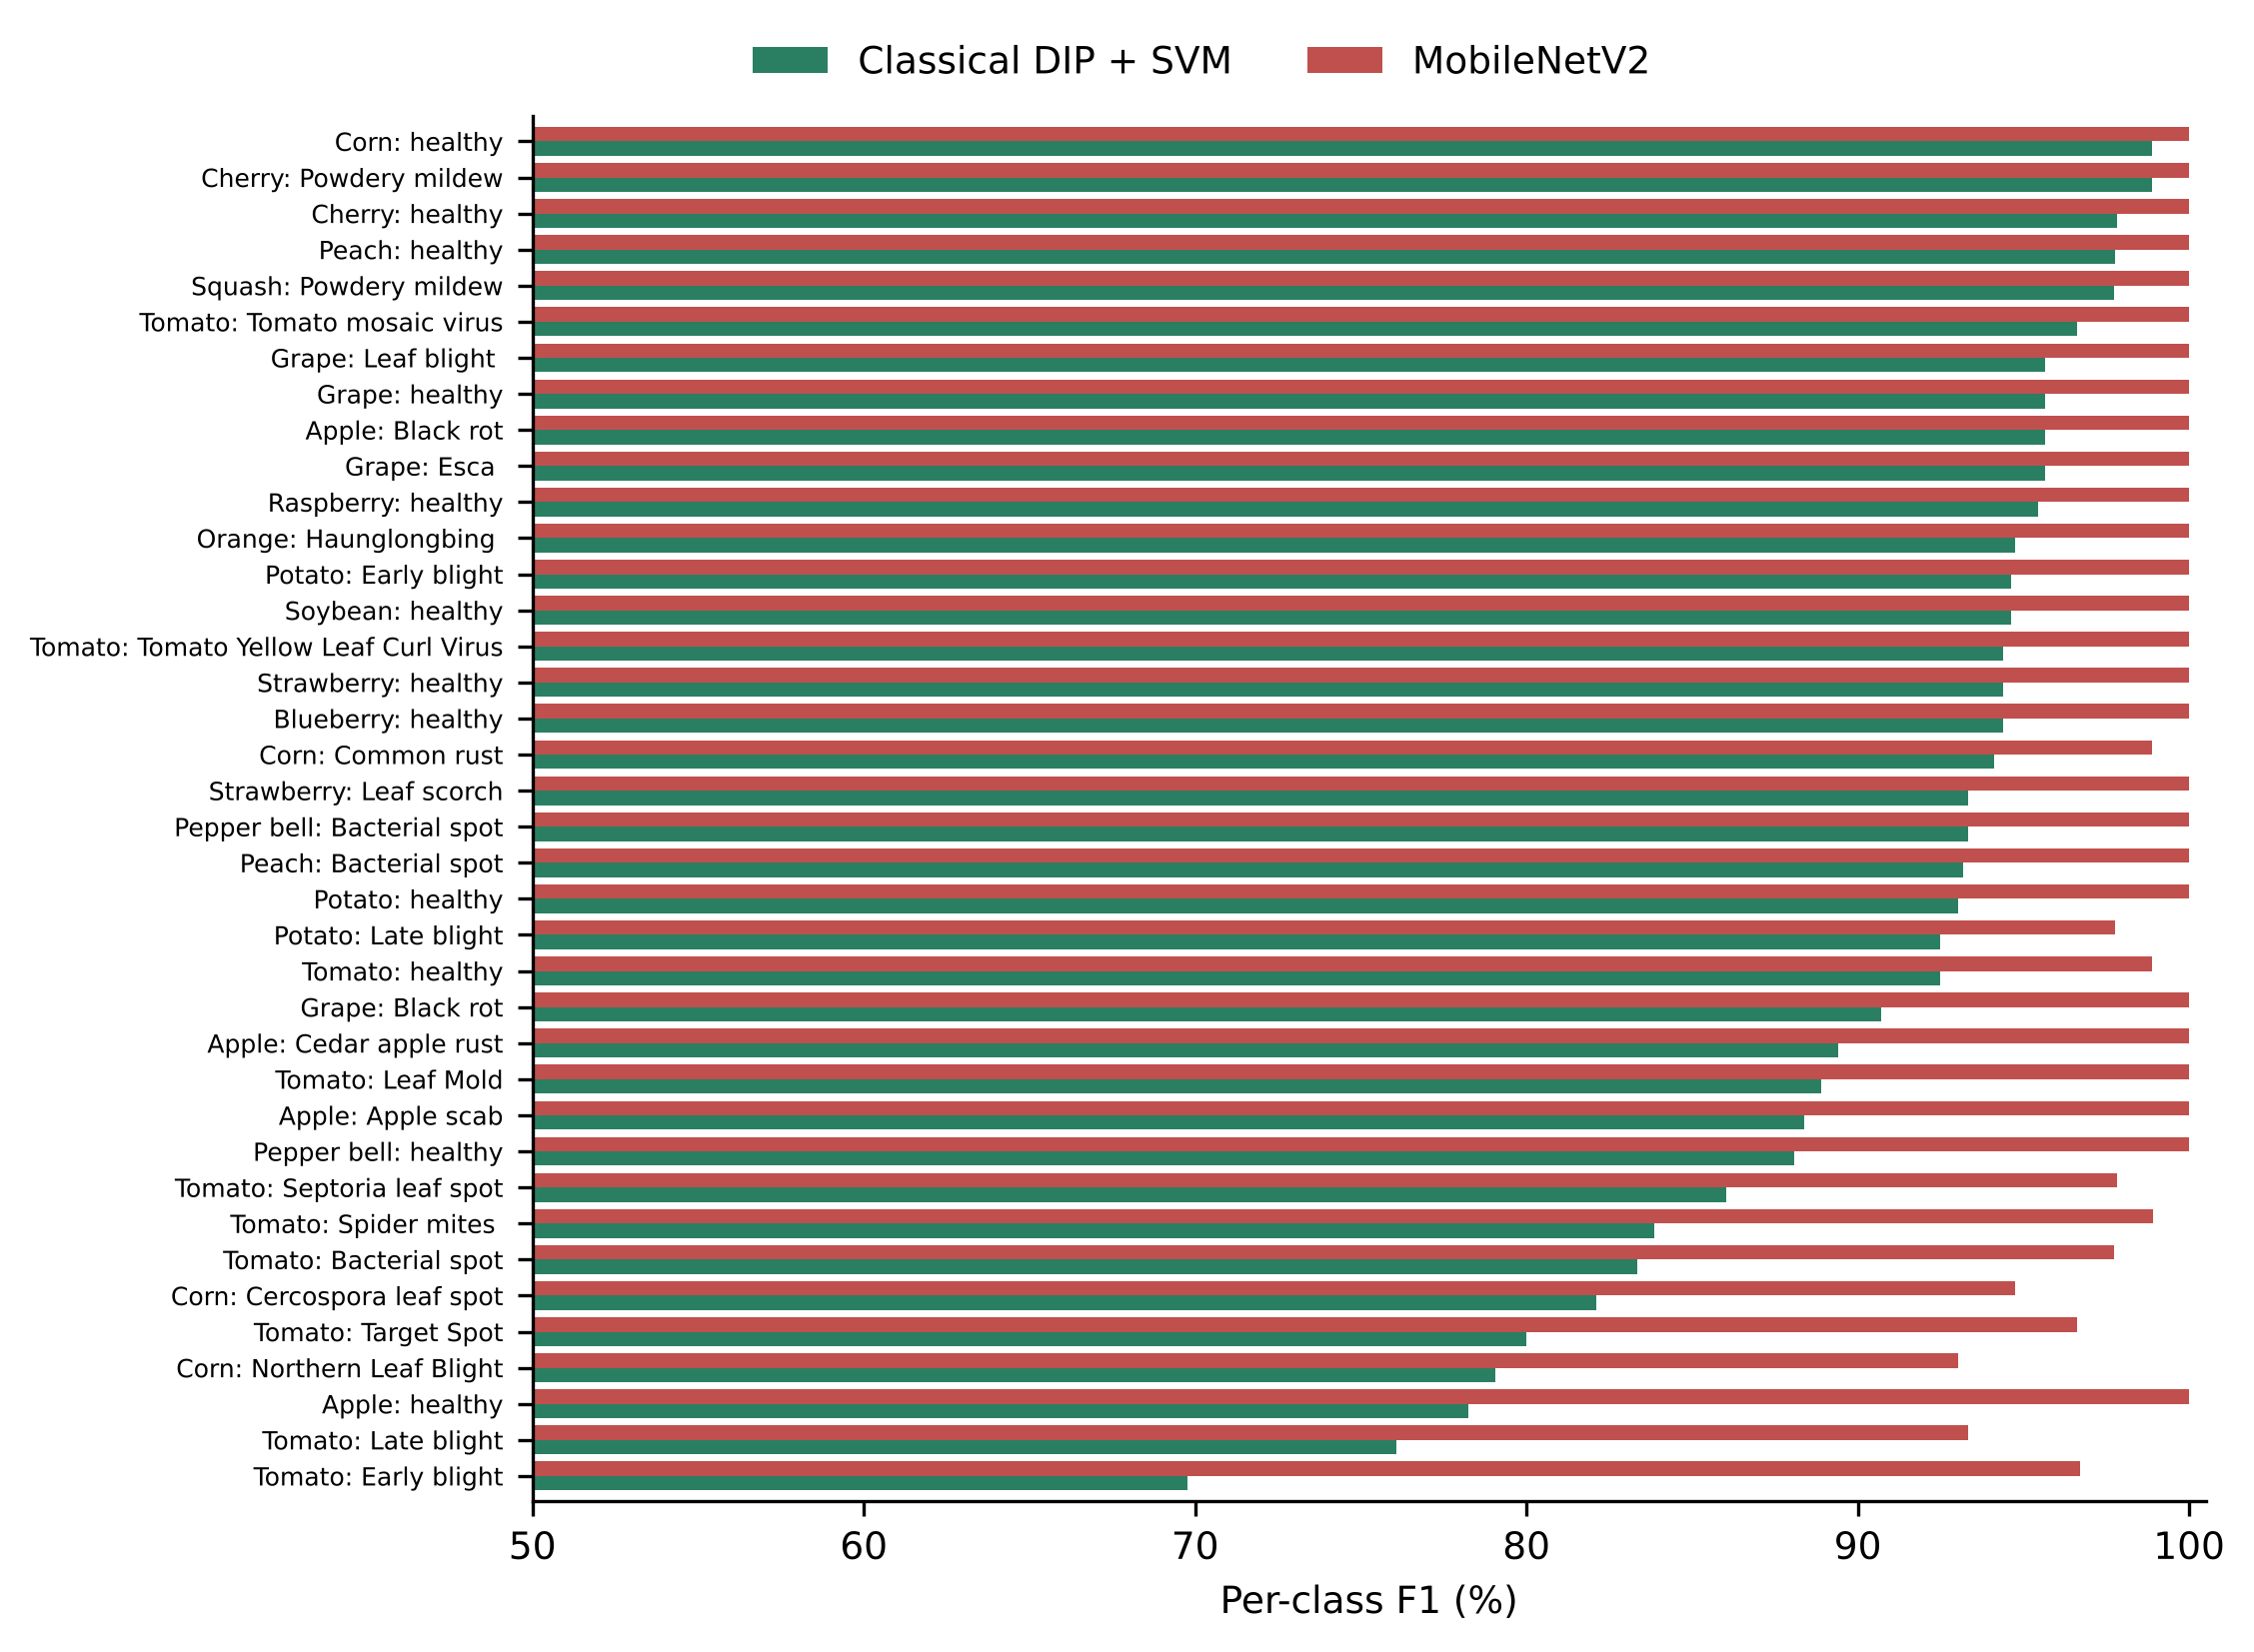

fig_confusion_svm.png


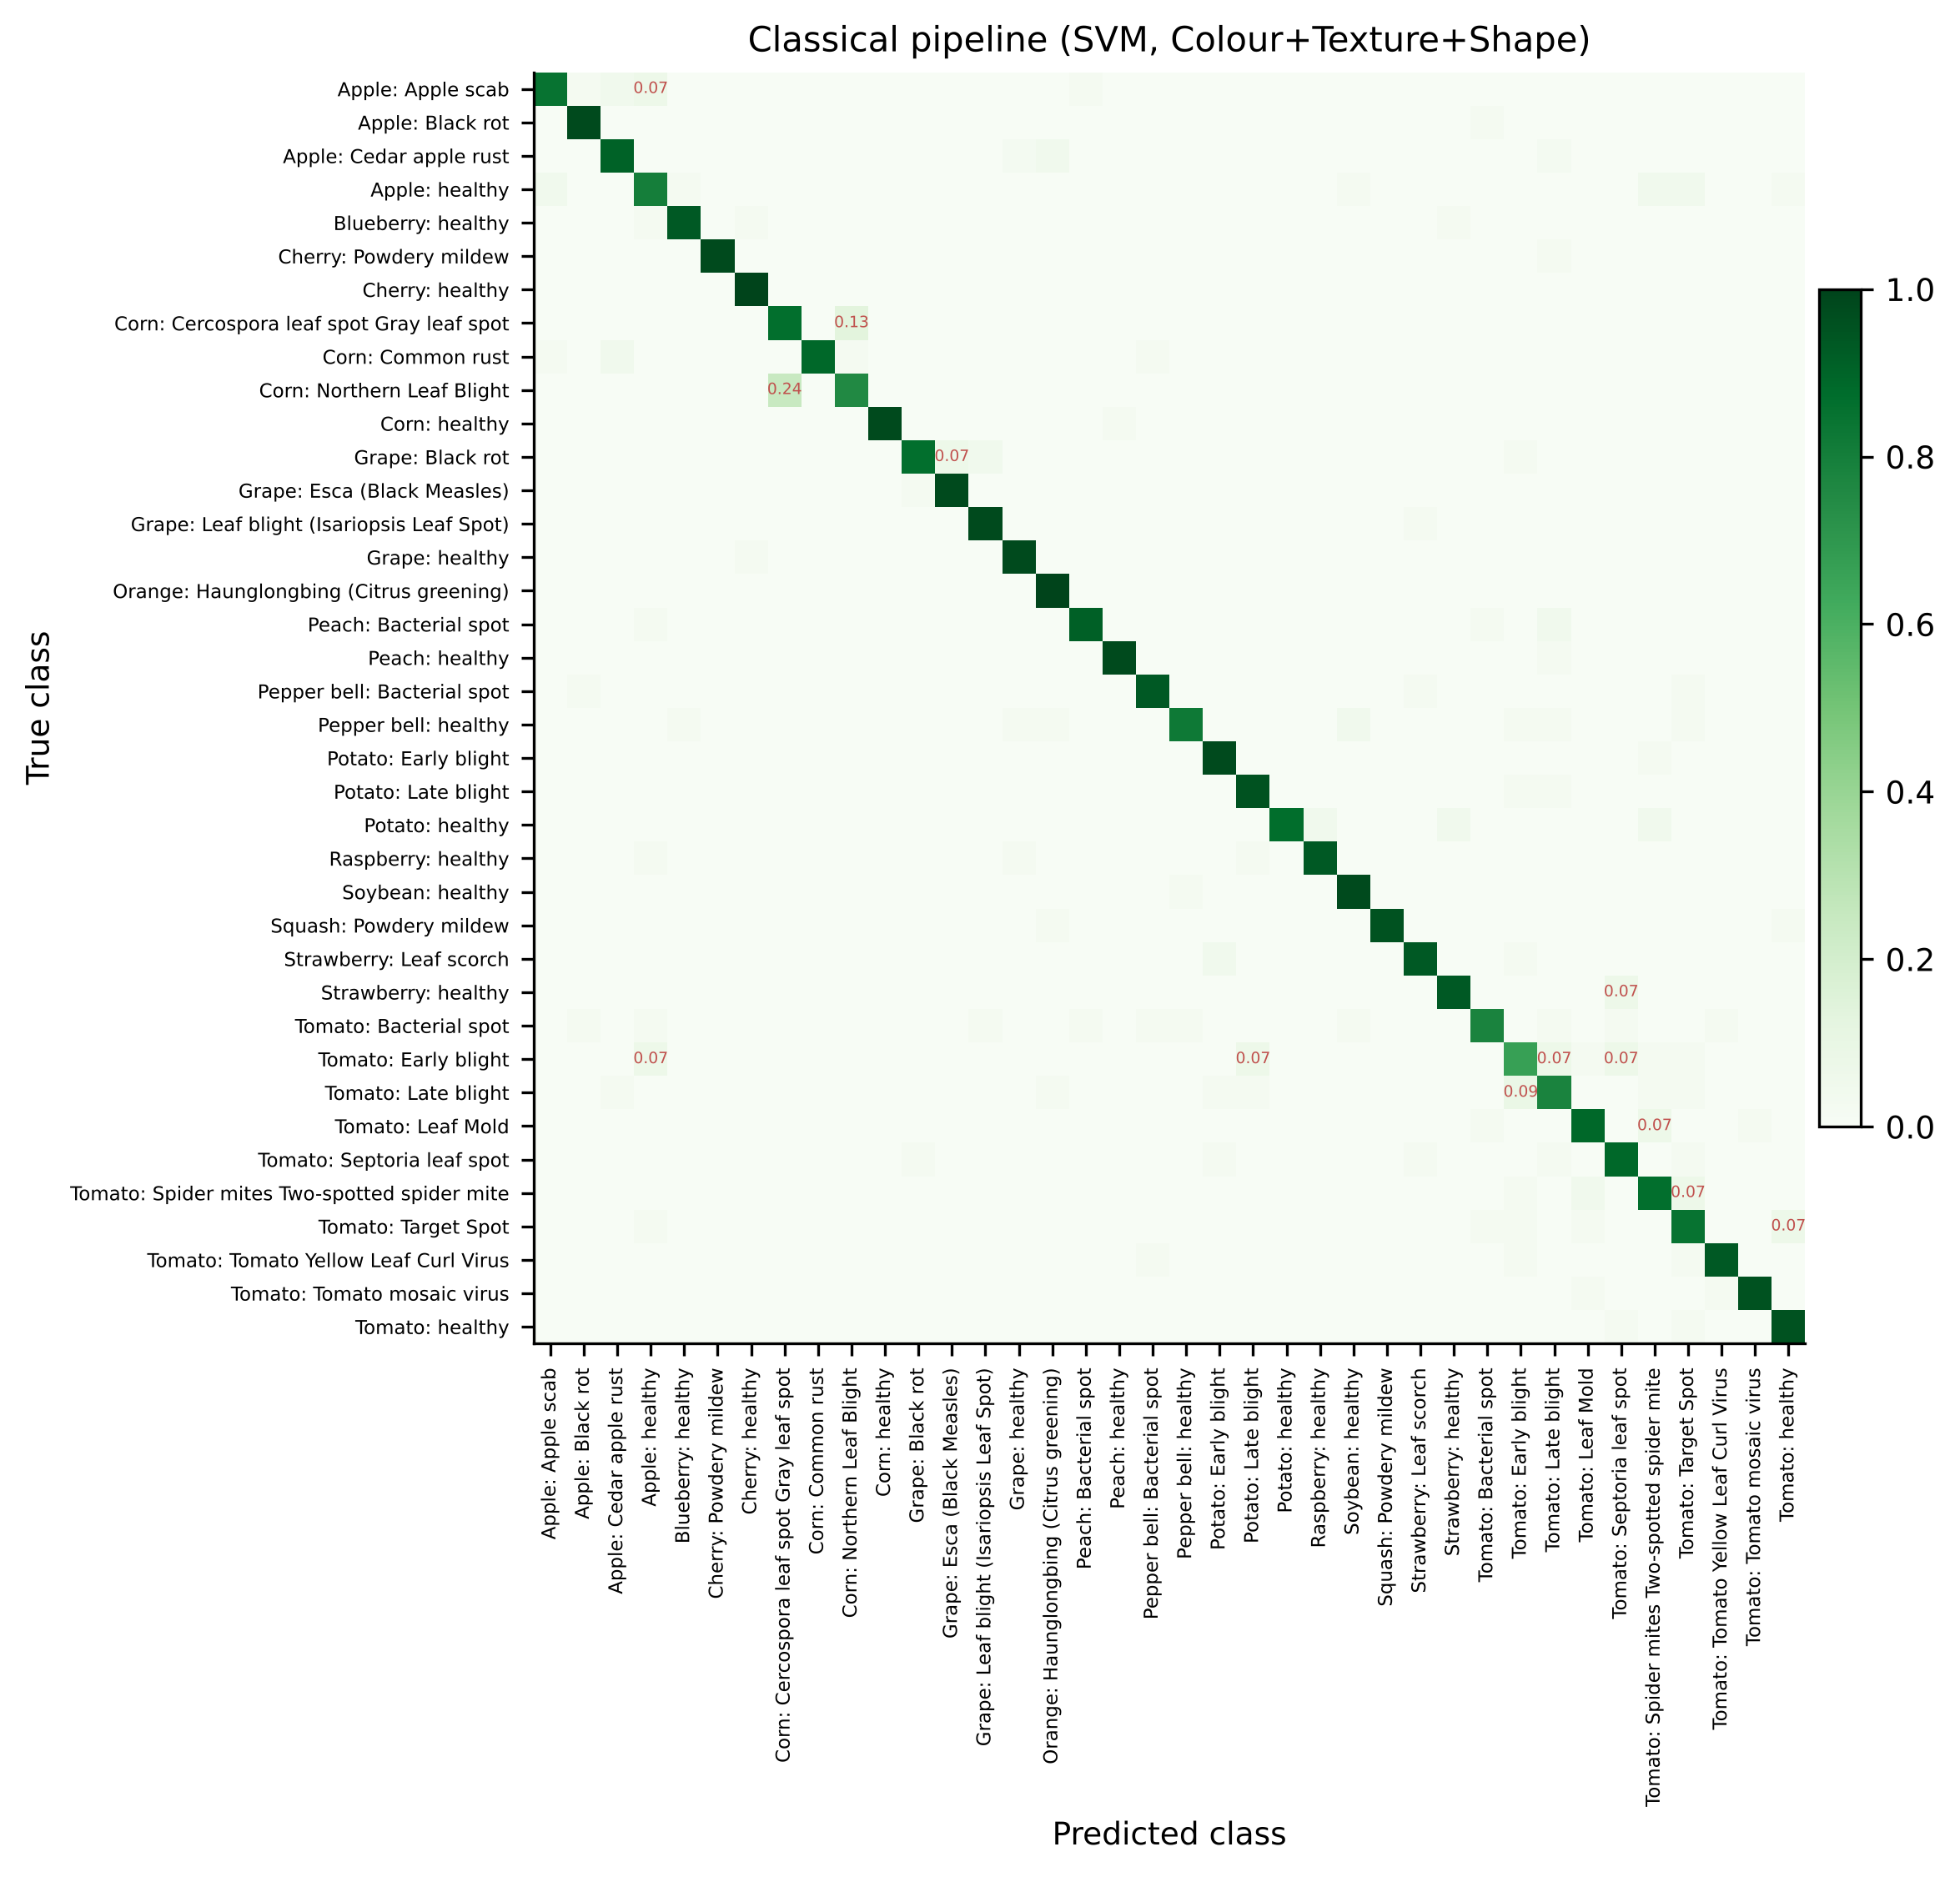

fig_confusion_cnn.png


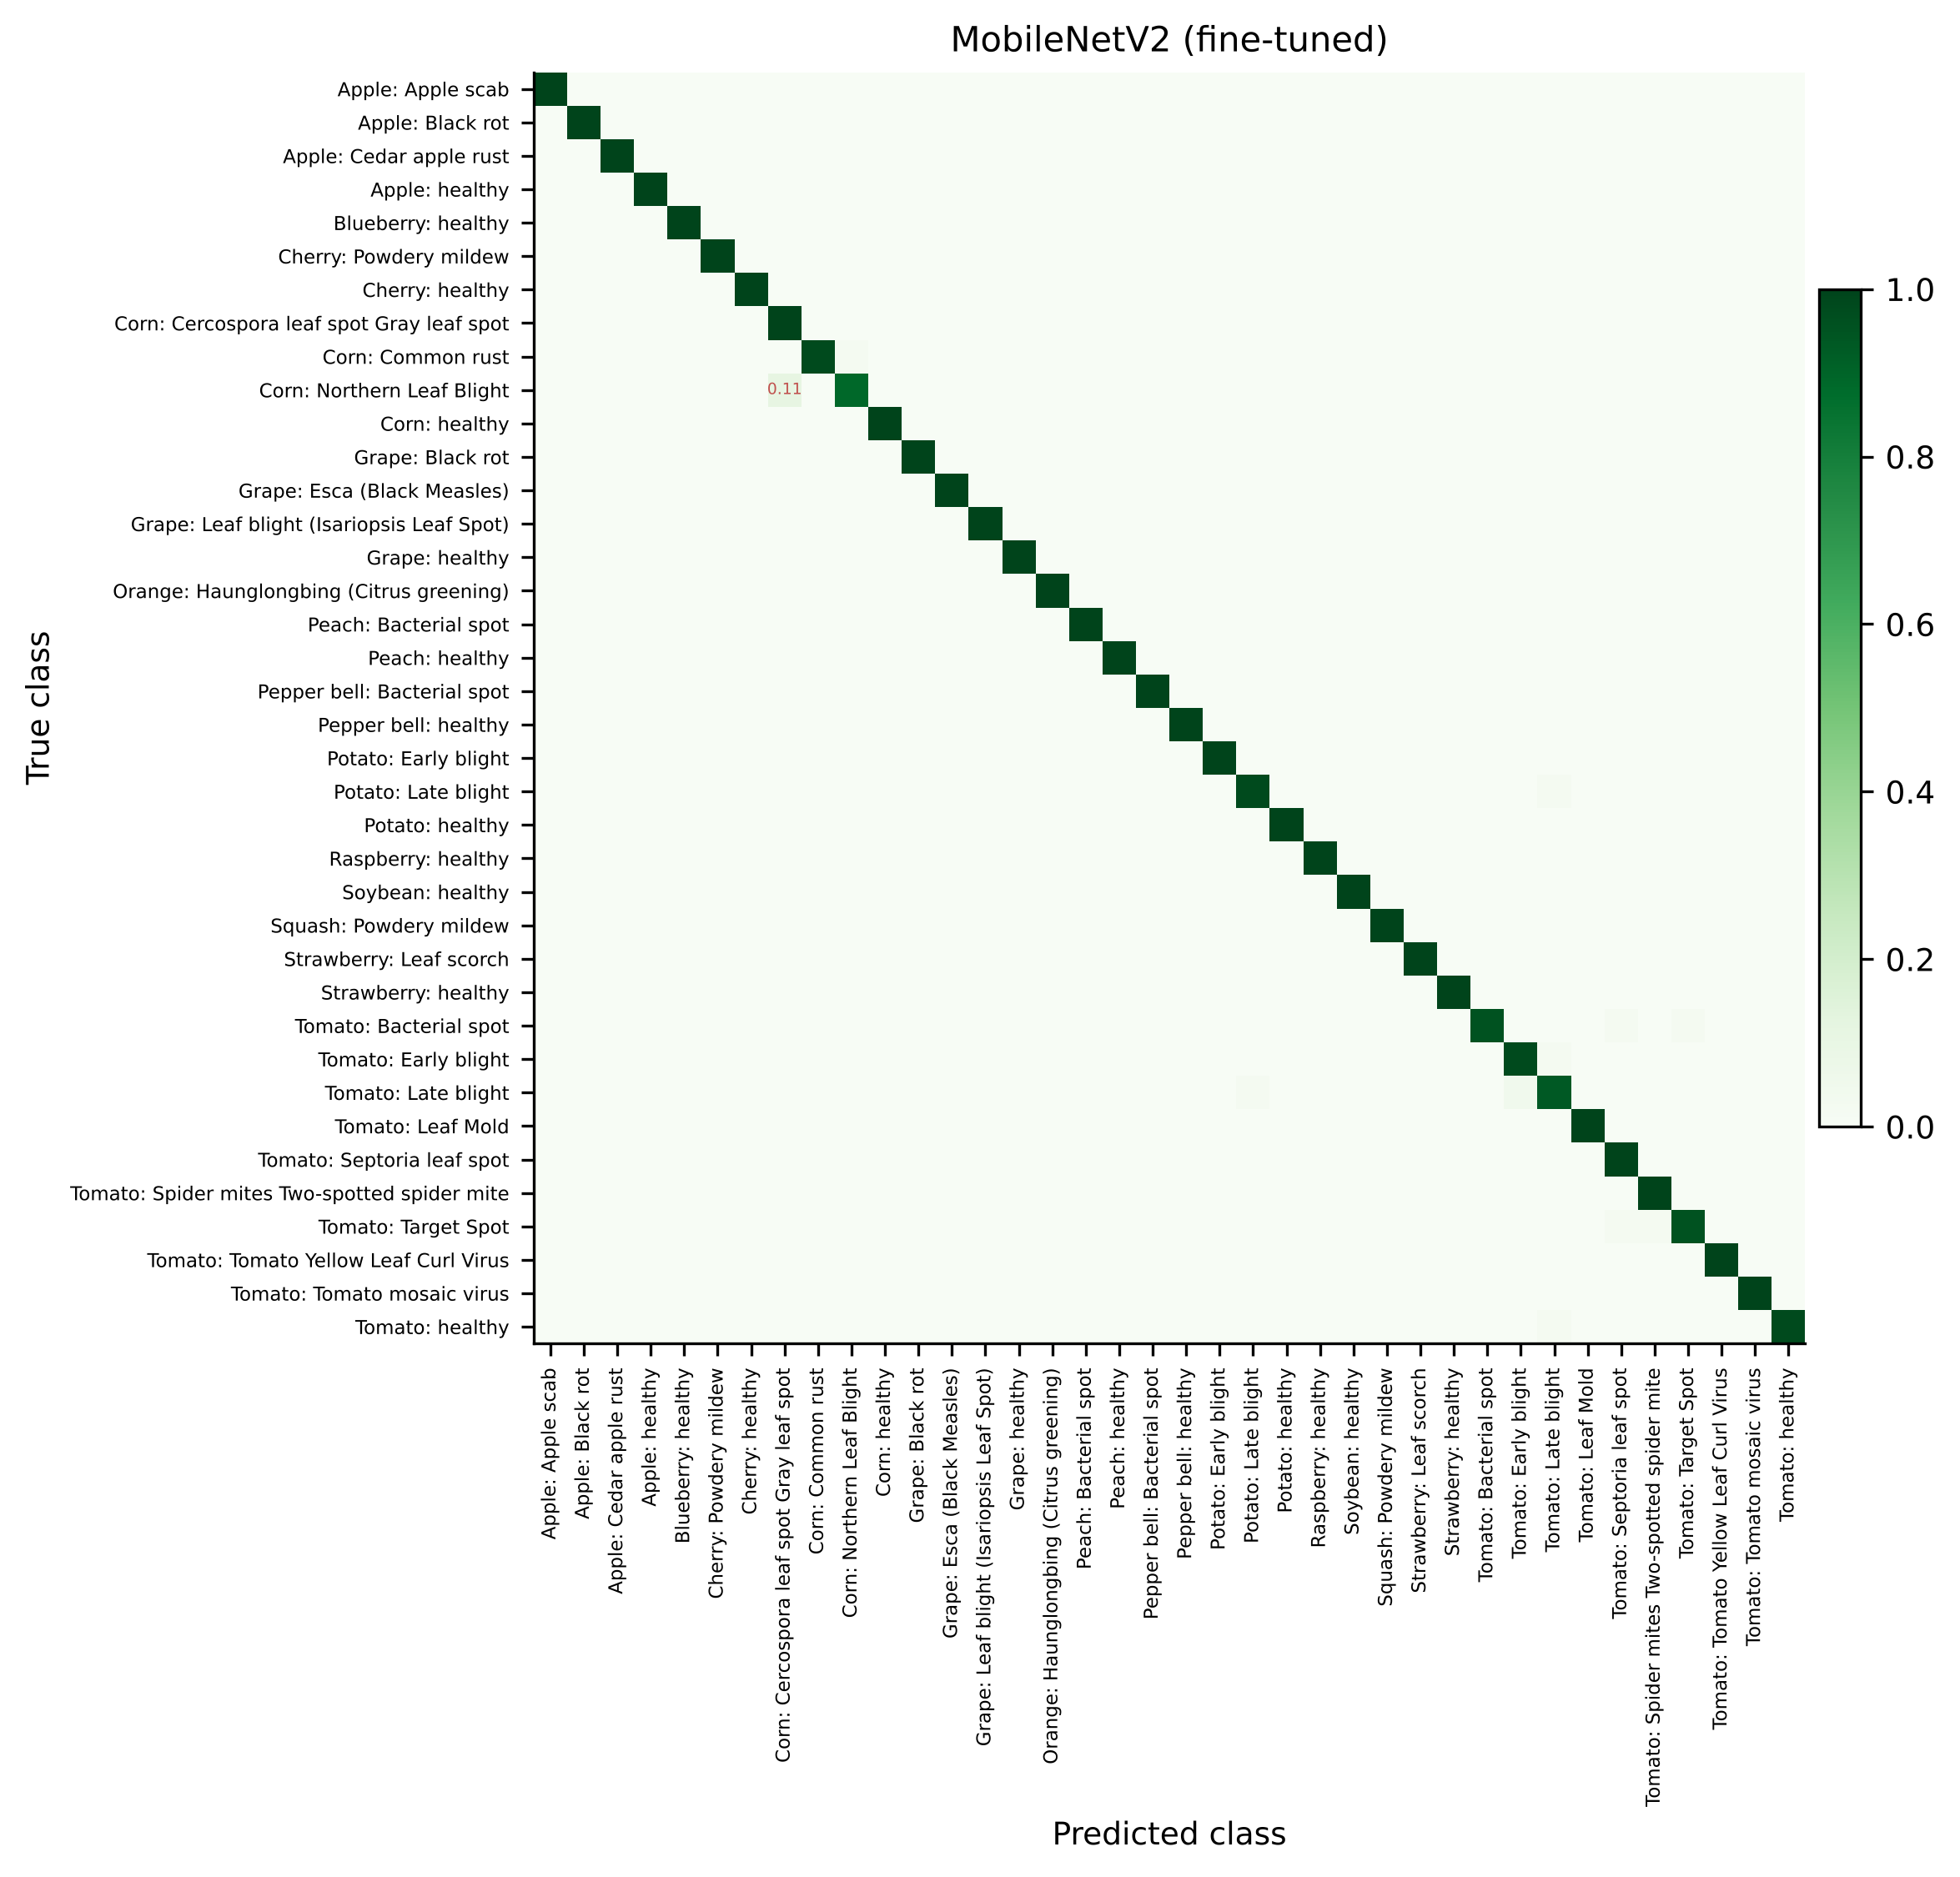

fig_degradations.png


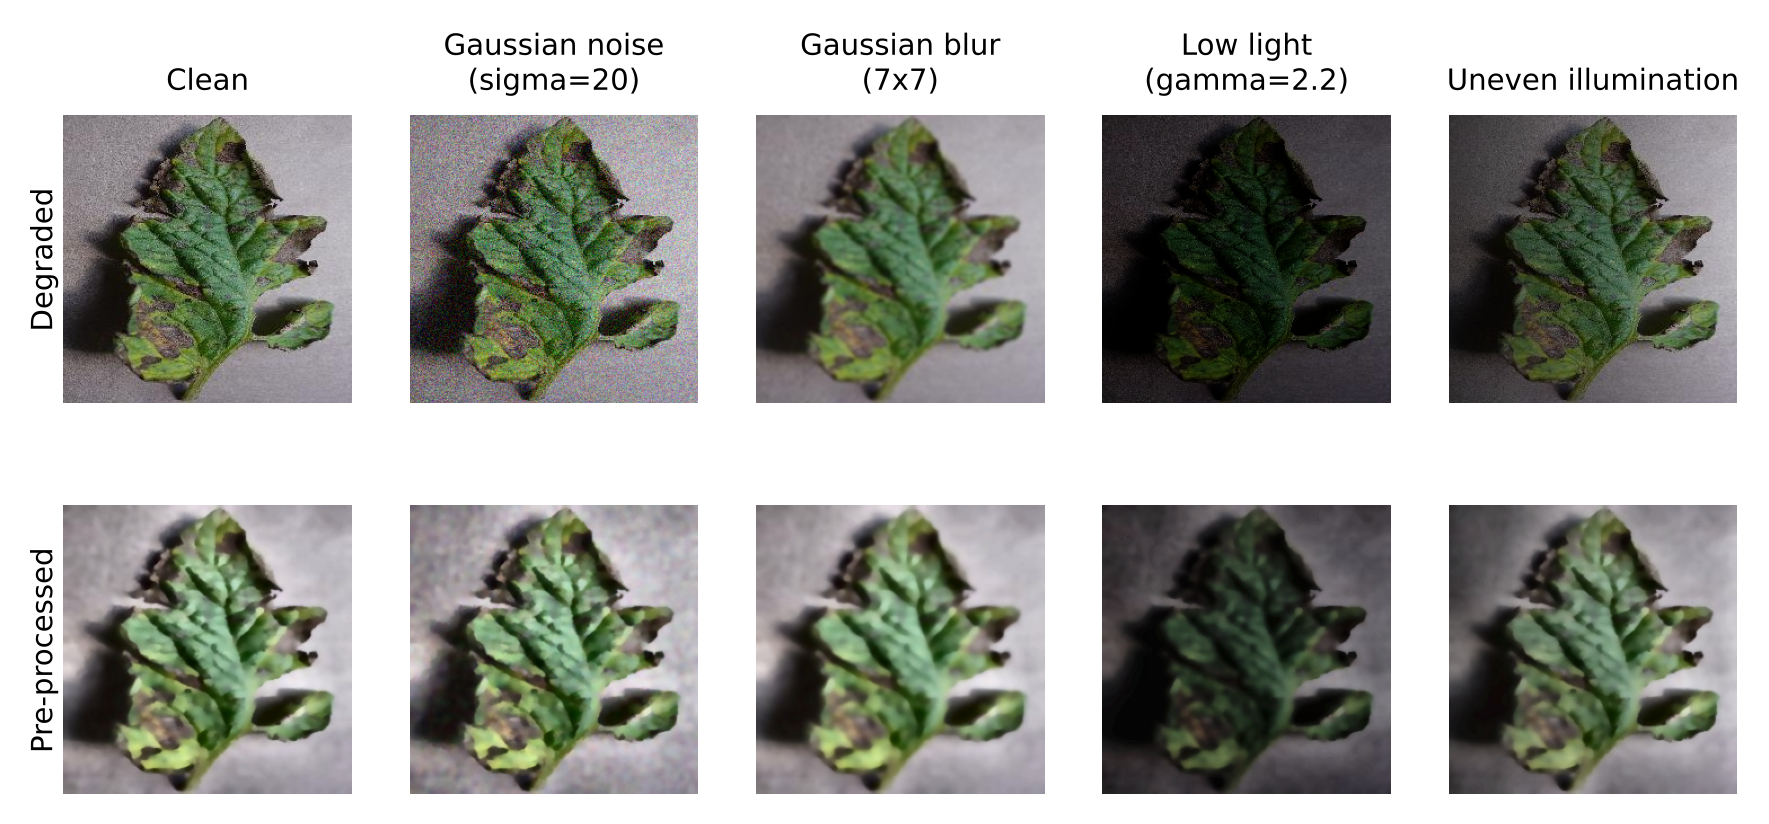

fig_robustness.png


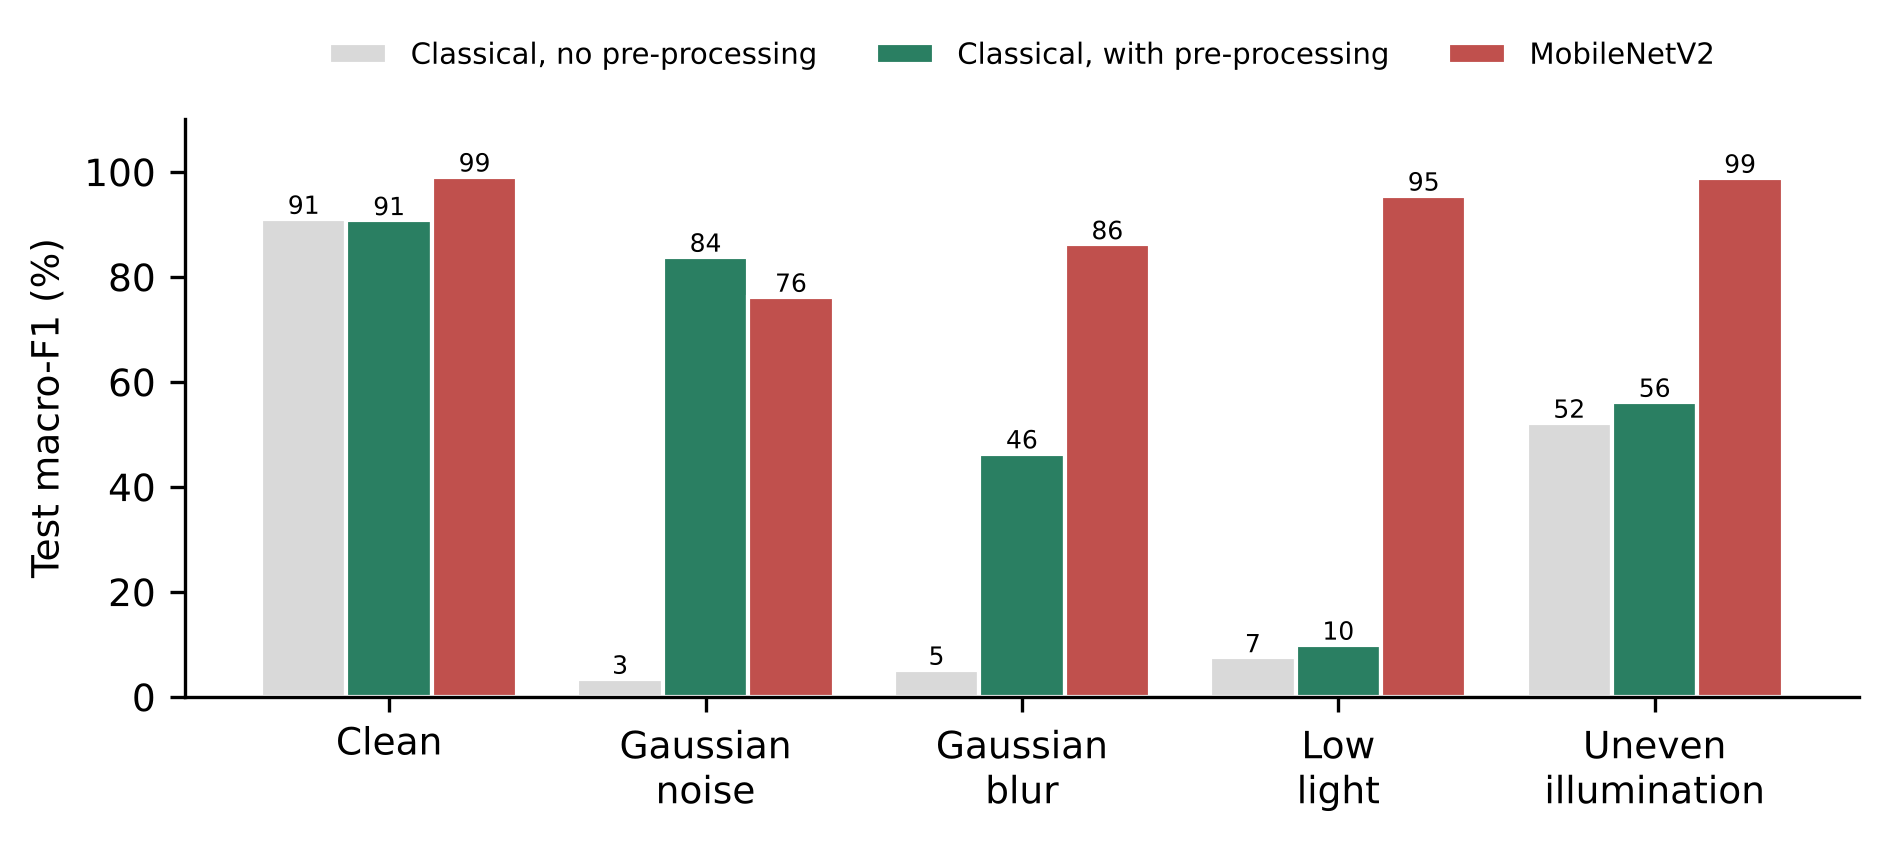

In [30]:
for f in ['fig_dataset_distribution.png', 'fig_segmentation_pipeline.png', 'fig_segmentation_iou.png', 'fig_lesion_ratio.png',
          'fig_feature_groups.png', 'fig_cnn_training.png', 'fig_per_class_f1.png', 'fig_confusion_svm.png',
          'fig_confusion_cnn.png', 'fig_degradations.png', 'fig_robustness.png']:
    print(f); display(ShowImage(os.path.join(FIG_DIR, f), width=850))

In [31]:
pd.read_csv(os.path.join(TABLE_DIR, 'robustness_macro_f1.csv')).round(4)

,degradation,MobileNetV2,with pre-processing,without pre-processing
0,clean,0.9906,0.9076,0.9100
1,gaussian_noise,0.7616,0.8379,0.0341
2,gaussian_blur,0.8619,0.4633,0.0512
3,low_light,0.9544,0.0989,0.0749
4,uneven_illumination,0.9883,0.5616,0.5217


In [32]:
json.load(open(os.path.join(TABLE_DIR, 'cnn_efficiency.json')))

{'latency_ms_per_image_1thread': 15.281696319580078,
 'checkpoint_mb': 9.331339,
 'parameters': 2272550}

## 8. Inference on a single leaf
End-to-end prediction with both pipelines for one test image.

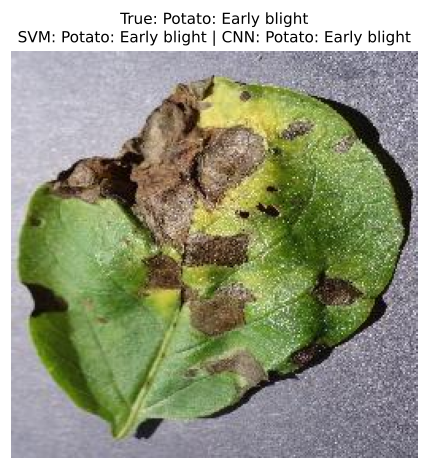

In [33]:
svm = joblib.load(os.path.join(MODEL_DIR, 'svm_best.joblib'))
best_groups = FEATURE_SETS[res['best_feature_set']]
cnn_model = load_trained(len(classes), os.path.join(MODEL_DIR, 'mobilenetv2_best.pt'))
row = df[df.split == 'test'].sample(1, random_state=7).iloc[0]
rgb = load_rgb(row.path)
feat = extract_all(rgb); xvec = np.hstack([feat[g] for g in best_groups])[None]
svm_pred = classes[int(svm.decision_function(xvec).argmax())]
with torch.no_grad():
    cnn_pred = classes[int(cnn_model(EVAL_TF(Image.fromarray(rgb))[None]).argmax())]
plt.imshow(rgb); plt.axis('off'); plt.title(f'True: {pretty(row["class"])}\nSVM: {pretty(svm_pred)} | CNN: {pretty(cnn_pred)}'); plt.show()

## 9. Conclusion
K-means clustering on the CIELAB chromaticity plane with morphological refinement segments the leaf with a mean IoU of 0.92 against the PlantVillage reference masks. The hand-crafted colour, texture and shape features reach 90.7% accuracy on 38 classes with an SVM, and the fine-tuned MobileNetV2 reaches 99.1%. The pre-processing stage makes the classical pipeline robust to noise and blur (macro-F1 under Gaussian noise rises from 3.4% to 83.8%). Leaf masking keeps the classifier from exploiting the PlantVillage background bias. See `paper/` for the full discussion.